# ENG5338 CW2 钢板缺陷分类

**第 5 组。** 使用 1,941 条记录、27 个数值特征，对逻辑回归、RBF 支持向量机、随机森林和直方图梯度提升进行比较。数据包含七类缺陷，没有正常钢板类别。

项目设定每类最低折外召回率不低于 0.60，100 条记录批量预测的 P95 不超过 20 毫秒。这些是课程场景假设。

**RBF 支持向量机是开发阶段优选，尚不能直接部署。** 冻结流水线采用中位数填补、标准化，参数为 `C=33.33333333333333`、`gamma=0.03`、`class_weight="balanced"`。留出集中 pastry 的召回率为 18/32 = 0.5625，未达目标。

选择 **CW2 portable** 内核运行全部单元格；程序会从当前目录或上级目录定位项目资源。变量、参数名和原始数据字段保留原样。

## 中文便携复现版

中文版参考文件保存在 original/，归档时仅统一组号标识。本入口提供环境、路径和复现校验适配。请从仓库根目录打开，并使用 Python 3.11 与 requirements.txt 的固定版本。安装依赖需要联网。

数据、冻结模型、历史预测均按 SHA-256 校验。新训练、计时和差异诊断单独输出；历史结果不被覆盖。留出集仅重放已保存预测，不进行新的预测。不同电脑的计时和浮点结果可能变化。


In [1]:
from pathlib import Path
import hashlib, json, os, sys
for key in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS','NUMEXPR_NUM_THREADS']:
    os.environ[key]='1'

def find_project_root(start):
    for folder in (start, *start.parents):
        if (folder/'input_manifest.json').is_file() and (folder/'data/steel-plates-faults.csv').is_file():
            return folder
    raise FileNotFoundError('Open this notebook inside the integrated CW2 project.')

INTEGRATED_ROOT=find_project_root(Path.cwd().resolve())
sys.path.insert(0,str(INTEGRATED_ROOT))
from portable_support import verify_inputs, check_environment
check_environment(INTEGRATED_ROOT)
print('包内输入已校验：', verify_inputs(INTEGRATED_ROOT))
(INTEGRATED_ROOT/'qa').mkdir(exist_ok=True)
FROZEN_DECISION=json.loads((INTEGRATED_ROOT/'frozen_decision.json').read_text())
FROZEN_BASE_REPS={'LogisticRegression':'LogisticRegression_09','RBF_SVC':'RBF_SVC_11',
 'RandomForest':'RandomForest_12','HistGradientBoosting':'HistGradientBoosting_07'}
FROZEN_KERNEL_PARAMS=json.loads((INTEGRATED_ROOT/'fixed_reference_params.json').read_text())
assert hashlib.sha256((INTEGRATED_ROOT/'archive/frozen_RBF_SVM.joblib').read_bytes()).hexdigest()==FROZEN_DECISION['model_sha256']
assert not FROZEN_DECISION['test_metrics_used_for_this_decision']

import builtins as _builtins
import re as _re
from IPython.display import display as _display
from matplotlib.text import Text
from matplotlib import font_manager
_available_fonts={f.name for f in font_manager.fontManager.ttflist}
CW2_FONT=next((name for name in ['Microsoft YaHei','Noto Sans CJK SC','Noto Sans CJK JP','SimHei','PingFang SC','WenQuanYi Zen Hei'] if name in _available_fonts),'DejaVu Sans')
if CW2_FONT=='DejaVu Sans':
    _builtins.print('未找到中文字体；请安装 Noto Sans CJK，图中文字可能缺字。')

UI_TEXT = {'Training class distribution': '训练集类别分布', 'Training feature correlations': '训练集特征相关性', 'Training standard deviation (log scale)': '训练集标准差（对数尺度）', 'Feature scales': '特征量级', 'Training samples': '训练样本数', 'Defect class': '缺陷类别', 'Training macro F1': '训练集宏平均 F1', 'Validation macro F1': '验证集宏平均 F1', 'Internal validation macro F1': '内部验证宏平均 F1', 'Macro F1': '宏平均 F1', 'Out-of-fold class recall (constraint: every class >= 0.60)': '各类折外召回率（每类至少 0.60）', '100-row prediction P95 (ms)': '100 条记录预测 P95（毫秒）', 'Worst of five round P95 (ms / 100 rows)': '五轮中最差 P95（毫秒／100 条记录）', 'P95 (ms / 100 rows)': 'P95（毫秒／100 条记录）', '20 ms limit': '20 毫秒上限', 'Training rows': '训练样本数', 'Median fit time (seconds)': '拟合耗时中位数（秒）', 'Median fit seconds': '拟合耗时中位数（秒）', 'Timing round': '计时轮次', 'Linear versus RBF SVM representatives': '线性核与 RBF 核支持向量机比较', 'Mean fold ROC (one class versus rest)': '五折平均 ROC（一类对其余）', 'Mean fold PR (one class versus rest)': '五折平均 PR（一类对其余）', 'False positive rate': '假阳性率', 'True positive rate': '真正率', 'Validation macro F1 decrease': '验证集宏平均 F1 下降值', 'Frozen RBF SVM holdout counts': '冻结 RBF 支持向量机留出集混淆计数', 'Recall by actual class': '按真实类别归一化的召回率', 'Predicted': '预测类别', 'Actual': '真实类别', 'Precision': '精确率', 'Recall': '召回率', 'Training': '训练集', 'Validation': '验证集', 'family': '模型', 'feature': '特征', 'class': '类别', 'HistGradientBoosting': '直方图梯度提升', 'LogisticRegression': '逻辑回归', 'RandomForest': '随机森林', 'RBF_SVC': 'RBF支持向量机', 'RBF SVM': 'RBF支持向量机', 'SVM': '支持向量机', 'linear': '线性核', 'rbf': 'RBF核', 'Frozen before test:': '测试前冻结的参数：', 'Run:': '结果目录：', 'Learning curves repeat': '学习曲线重复', 'Cost measurement complete:': '资源测量完成：', 'Part A verified; no holdout predictions:': 'A 部分检查通过，尚未预测留出集：', 'Part A automatic ranking (descriptive):': 'A 部分自动排序（仅作描述）：', 'Supplement run:': '补充实验目录：', 'five round P95:': '五轮 P95：', 'feasible:': '开发约束通过：', 'min OOF recall=': '最低折外召回率=', 'min recall=': '最低召回率=', 'CV F1=': '验证 F1=', 'Permutation importance:': '置换重要性：', 'fold': '折', 'Current reproduction timing (separate from historical selection):': '本次复现计时（与历史选型分开）：', 'Reusing the single frozen holdout prediction record; no new holdout prediction.': '读取已有冻结留出集预测，不进行新的预测。', 'All-class recall threshold met:': '全部类别召回率达标：', 'Model and parameters remain unchanged regardless of the holdout result.': '无论留出集结果如何，模型和参数均保持不变。', 'Integration checks:': '整合检查：', 'Checks passed:': '检查通过：', 'Results:': '结果目录：', 'FAILED': '未完成', 'refinement': '局部细化', 'coarse': '粗搜索', 'Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.': '求解器提前终止（max_iter=100000）；可检查 StandardScaler 或 MinMaxScaler 预处理。'}
DISPLAY_COLUMNS = {'all': '全部', 'train': '开发集', 'test': '留出集', 'version': '版本', 'family': '模型', 'kernel': '核函数', 'candidate_id': '配置编号', 'stage': '搜索阶段', 'params': '参数', 'class': '类别', 'train_macro_f1': '训练集宏平均F1', 'validation_macro_f1': '验证集宏平均F1', 'validation_macro_f1_std': '验证F1折间标准差', 'validation_accuracy': '验证准确率', 'train_validation_gap': '训练验证差距', 'oof_macro_f1': '折外宏平均F1', 'oof_min_class_recall': '最低类别折外召回率', 'quality_pass': '质量约束通过', 'mean_fold_fit_seconds': '平均每折拟合秒数', 'candidate_wall_seconds': '配置总耗时秒', 'recall_deficit': '召回率缺口', 'prediction_median_ms': '预测中位数毫秒', 'prediction_p95_ms': '预测P95毫秒', 'selection_fit_seconds': '完整拟合秒数', 'latency_pass': '耗时约束通过', 'feasible': '开发约束通过', 'constraint_violation': '约束违背量', 'pooled_p95_ms': '合并P95毫秒', 'worst_round_p95_ms': '最差轮P95毫秒', 'round_p95_values': '各轮P95', 'timing_rounds_passed': '计时通过轮数', 'stable_latency_pass': '五轮耗时通过', 'stable_feasible': '开发约束通过', 'violation': '约束违背量', 'fit_median_seconds': '拟合中位数秒', 'fit_q25_seconds': '拟合耗时下四分位数秒', 'fit_q75_seconds': '拟合耗时上四分位数秒', 'serialized_kib': '模型体积KiB', 'serialized_model_kib': '模型体积KiB', 'baseline_rss_mib': '基线RSS内存MiB', 'sampled_peak_process_rss_mib': '采样进程峰值RSS内存MiB', 'sampled_peak_fit_increment_mib': '采样拟合内存增量MiB', 'rss_samples': 'RSS采样次数', 'precision': '精确率', 'recall': '召回率', 'f1-score': 'F1', 'support': '样本数', 'recall_wilson95_low': '召回率Wilson95%下限', 'recall_wilson95_high': '召回率Wilson95%上限', 'recall_constraint_pass': '召回率约束通过', 'roc_auc_mean': 'ROC面积均值', 'roc_auc_sd': 'ROC面积标准差', 'ap_mean': '平均精确率均值', 'ap_sd': '平均精确率标准差', 'prevalence': '类别比例', 'run': '实验', 'rounds_passed': '通过轮数', 'total_rounds': '总轮数', 'test_accuracy': '留出集准确率', 'test_macro_f1': '留出集宏平均F1', 'test_min_class_recall': '留出集最低类别召回率', 'test_recall_constraint_pass': '留出集召回率约束通过', 'rows': '样本数', 'test_evaluation_count': '留出集预测次数', 'retuned_after_test': '测试后调参', 'independent_external_test': '独立外部测试', 'evaluated_at_utc': '评估UTC时间', 'holdout_previously_used_in_cw1': '留出集曾用于CW1', 'holdout_previously_used_in_original_cw2': '留出集曾用于原CW2'}

def translate_text(value):
    for old, new in sorted(UI_TEXT.items(), key=lambda item: -len(item[0])):
        if _re.fullmatch('[A-Za-z_]+',old):
            value=_re.sub(r'(?<![A-Za-z0-9_])'+_re.escape(old)+r'(?![A-Za-z0-9_])',lambda match:new,value)
        else:
            value=value.replace(old,new)
    return value

def print(*values, **kwargs):
    _builtins.print(*(translate_text(value) if isinstance(value,str) else value for value in values), **kwargs)

def display(*values, **kwargs):
    for value in values:
        if isinstance(value,(pd.DataFrame,pd.Series)):
            value=value.copy()
            if isinstance(value,pd.DataFrame):
                value.columns=[DISPLAY_COLUMNS.get(str(x),str(x).replace('oof_recall_','折外召回率_')) for x in value.columns]
                for column in value.columns:
                    if value[column].dtype==object:
                        value[column]=value[column].map(lambda x:UI_TEXT.get(x,x) if isinstance(x,str) else x)
            value.index=[DISPLAY_COLUMNS.get(str(x),UI_TEXT.get(str(x),x)) for x in value.index]
        _display(value,**kwargs)

def localize_figure(fig):
    fig.canvas.draw()
    for item in fig.findobj(Text):
        item.set_text(translate_text(item.get_text()))
        item.set_fontfamily(CW2_FONT)
    for axis in fig.axes:
        for direction in ['x','y']:
            labels=getattr(axis,'get_'+direction+'ticklabels')()
            text=[translate_text(x.get_text()) for x in labels]
            if any(a!=b.get_text() for a,b in zip(text,labels)):
                getattr(axis,'set_'+direction+'ticks')(getattr(axis,'get_'+direction+'ticks')(),text)

print('Frozen before test:', FROZEN_DECISION['params'])


包内输入已校验： 22


测试前冻结的参数： {'kernel': 'rbf', 'C': 33.33333333333333, 'gamma': 0.03, 'class_weight': 'balanced'}


## A 部分 四模型比较

原始 48 个配置共用开发集的五折划分。使用保留的代表配置进行比较；新计时不会改变冻结的支持向量机选择。

In [2]:
from pathlib import Path
from datetime import datetime, timezone
from time import perf_counter, sleep
import hashlib
import importlib.metadata
import json
import os
import platform
import subprocess
import sys
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import seaborn as sns
from IPython.display import Markdown, display as _display
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import ParameterGrid, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from threadpoolctl import threadpool_info, threadpool_limits

SEED = 0
MIN_RECALL = 0.60
LATENCY_LIMIT_MS = 20.0
BATCH_SIZE = 100
PREDICTION_REPEATS = 100
FIT_REPEATS = 5
DATA_SHA256 = '9e9bfebd2ea8bf84f5264325fadace2194387991183cb20d52075ef72e2c858e'
PROJECT = INTEGRATED_ROOT / 'base'
DATA_PATH = INTEGRATED_ROOT / 'data' / 'steel-plates-faults.csv'
if not DATA_PATH.is_file():
    raise FileNotFoundError('Missing project data/steel-plates-faults.csv.')
RUN_DIR = PROJECT / 'results' / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
FIG_DIR = RUN_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=False)
warnings.filterwarnings('error', category=ConvergenceWarning)
sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams['font.sans-serif']=[CW2_FONT]
pd.set_option('display.max_columns', 20)
pd.set_option('display.precision', 4)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 160})

def json_default(x):
    if isinstance(x, Path): return str(x)
    if isinstance(x, np.generic): return x.item()
    if isinstance(x, np.ndarray): return x.tolist()
    raise TypeError(type(x).__name__)

def save_json(value, filename):
    (RUN_DIR / filename).write_text(json.dumps(value, ensure_ascii=False, indent=2,
        default=json_default, allow_nan=False), encoding='utf-8')

def save_table(frame, filename, index=False):
    frame.to_csv(RUN_DIR / filename, index=index, encoding='utf-8-sig')

def figure(fig, filename):
    localize_figure(fig)
    fig.savefig(FIG_DIR / filename, bbox_inches='tight')
    plt.show()
    plt.close(fig)

packages = ['numpy','pandas','scipy','scikit-learn','matplotlib','seaborn','psutil',
            'joblib','threadpoolctl','nbformat','nbclient','nbconvert','ipykernel']
runtime = {'python': sys.version, 'executable': sys.executable, 'os': platform.platform(),
    'processor': platform.processor(), 'physical_cpus': psutil.cpu_count(logical=False),
    'logical_cpus': psutil.cpu_count(), 'ram_gib': psutil.virtual_memory().total / 1024**3,
    'versions': {p:importlib.metadata.version(p) for p in packages},
    'thread_policy': 'Sequential CV; n_jobs=1; BLAS/OpenMP limited to 1 during fits and prediction.',
    'initial_threadpools': threadpool_info()}
save_json(runtime, 'environment.json')
save_json({'seed': SEED, 'test_size': .2, 'folds': 5, 'min_class_recall': MIN_RECALL,
    'batch_rows': BATCH_SIZE, 'prediction_p95_limit_ms': LATENCY_LIMIT_MS,
    'prediction_repeats': PREDICTION_REPEATS, 'fit_repeats': FIT_REPEATS,
    'holdout_previously_used_in_cw1': True, 'test_evaluation_count': 0}, 'protocol.json')
print('Run:', RUN_DIR)
display(pd.Series(runtime['versions'], name='version').to_frame())

结果目录： .\base\results\20261115_170610_319599


,版本
numpy,2.4.6
pandas,2.3.3
scipy,1.17.1
scikit-learn,1.7.2
matplotlib,3.11.2
seaborn,0.13.2
psutil,7.2.2
joblib,1.6.0
threadpoolctl,3.7.0
nbformat,5.11.1


## 1. 数据与划分

数据包含 27 个数值特征和七类缺陷。按类别分层进行 80/20 划分：1,552 条开发样本、389 条留出样本，种子为 0。缺失值、重复记录和特征量级均作检查；详细探索只用开发集。极端值与相关特征保留。

,全部,开发集,留出集
bumps,402,321,81
dirtiness,55,44,11
k_scatch,391,313,78
other_faults,673,538,135
pastry,158,126,32
stains,72,58,14
z_scratch,190,152,38


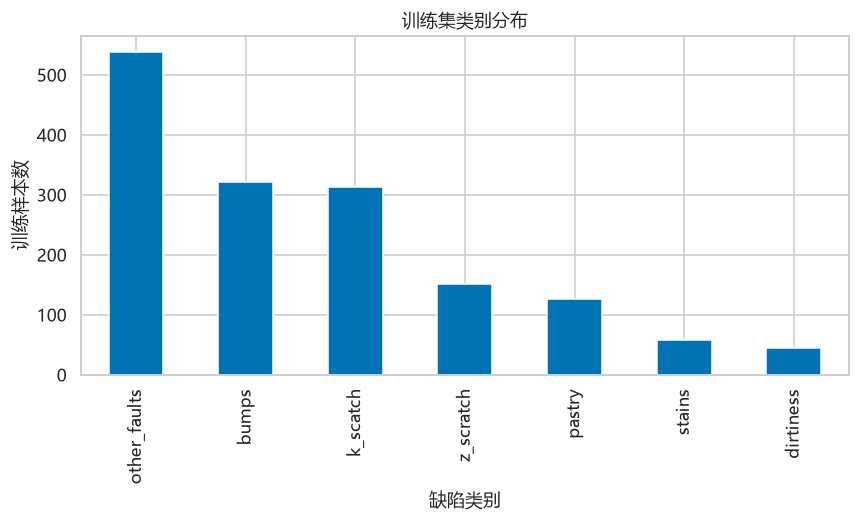

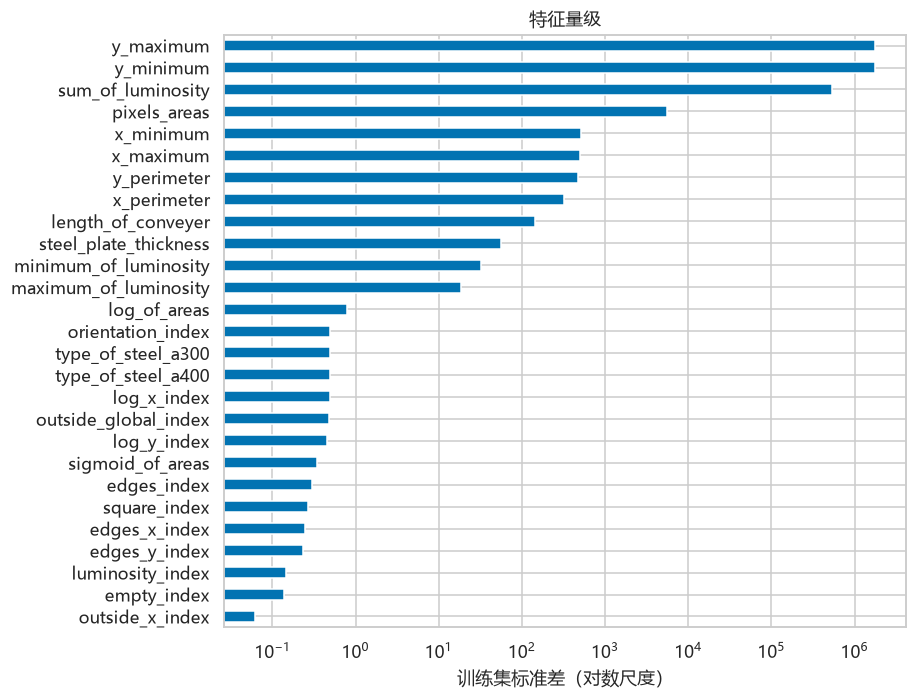

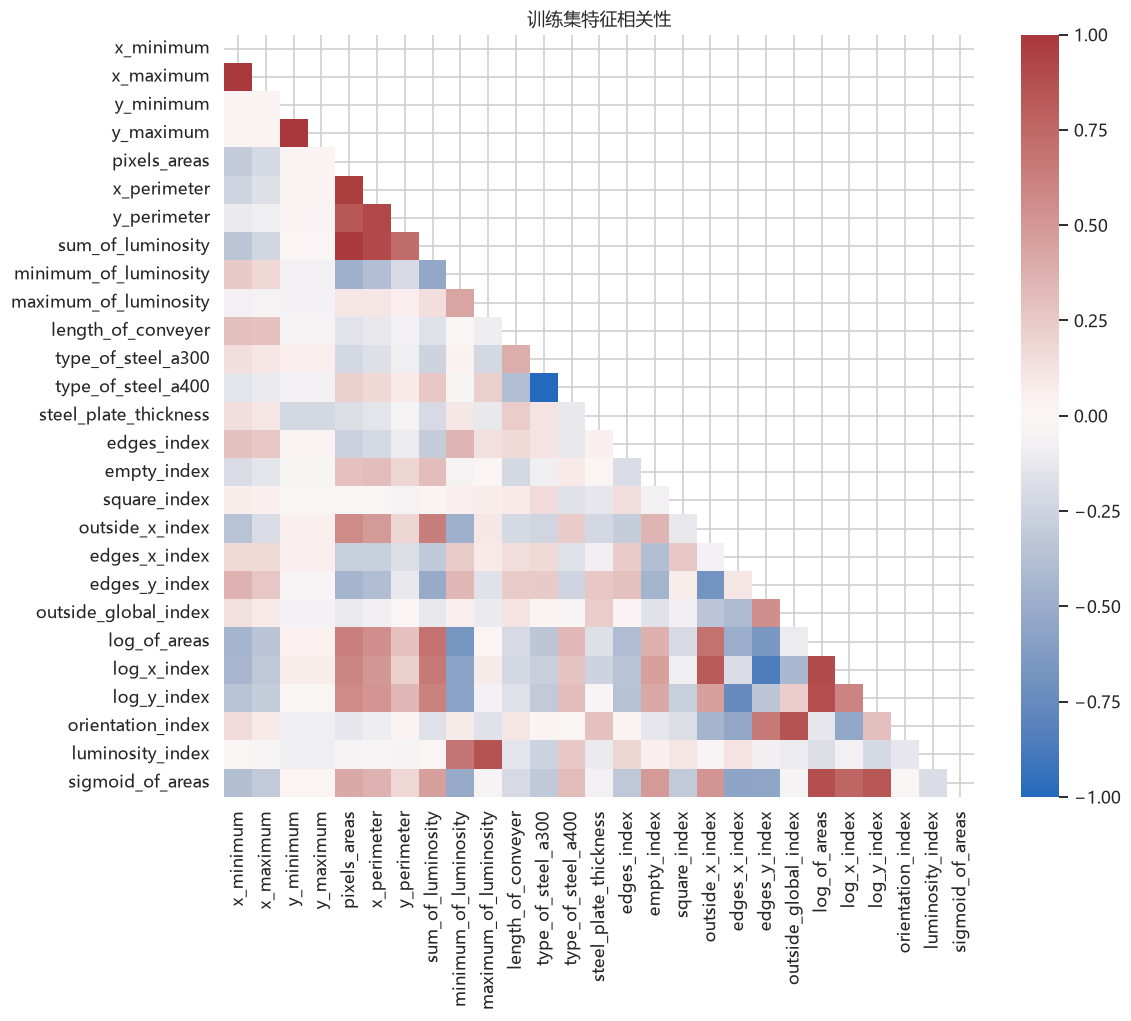

In [3]:
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == DATA_SHA256
df = pd.read_csv(DATA_PATH)
assert df.shape == (1941, 28) and 'fault_type' in df
X = df.drop(columns='fault_type')
y = df['fault_type']
assert all(pd.api.types.is_numeric_dtype(t) for t in X.dtypes)
assert np.isfinite(X.to_numpy(dtype=float)[~X.isna().to_numpy()]).all()
assert not X.duplicated().any(), 'Duplicate feature records require a grouped split review.'
assert y.notna().all() and y.nunique() == 7
classes = sorted(y.unique())
audit = {'rows':len(df), 'features':X.shape[1], 'classes':len(classes),
         'missing_feature_cells':int(X.isna().sum().sum()), 'duplicate_rows':int(df.duplicated().sum())}
save_json({'path':DATA_PATH, 'sha256':DATA_SHA256, **audit}, 'dataset_audit.json')
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=.2,random_state=SEED,stratify=y)
assert len(X_train) == 1552 and len(X_test) == 389
assert set(X_train.index).isdisjoint(X_test.index)
split = pd.DataFrame({'row_id':df.index,'csv_line':df.index+2,'split':'train'})
split.loc[X_test.index,'split'] = 'test'
save_table(split, 'split_membership.csv')
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(cv.split(X_train,y_train))
fold_ids = np.full(len(X_train),-1)
for fold,(fit,val) in enumerate(folds):
    assert not set(fit).intersection(val)
    fold_ids[val] = fold+1
save_table(pd.DataFrame({'row_id':X_train.index,'validation_fold':fold_ids}), 'cv_fold_membership.csv')
save_json(audit, 'audit.json')
counts = pd.DataFrame({'all':y.value_counts(),'train':y_train.value_counts(),'test':y_test.value_counts()}).loc[classes]
save_table(counts.rename_axis('class').reset_index(), 'class_counts.csv')
display(counts)
fig,ax = plt.subplots(figsize=(9,4))
y_train.value_counts().plot.bar(ax=ax)
ax.set(xlabel='Defect class',ylabel='Training samples',title='Training class distribution')
figure(fig,'01_class_distribution.png')
stats = X_train.describe().T
save_table(stats.rename_axis('feature').reset_index(), 'feature_statistics_train.csv')
fig,ax=plt.subplots(figsize=(8,7))
X_train.std().sort_values().plot.barh(ax=ax)
ax.set(xscale='log',xlabel='Training standard deviation (log scale)',title='Feature scales')
figure(fig,'02_feature_scales.png')
corr=X_train.corr()
fig,ax=plt.subplots(figsize=(11,9))
sns.heatmap(corr,mask=np.triu(np.ones_like(corr,dtype=bool)),vmin=-1,vmax=1,cmap='vlag',ax=ax)
ax.set_title('Training feature correlations')
figure(fig,'03_correlations.png')
correlation_pairs=[{'feature_1':a,'feature_2':b,'r':float(corr.loc[a,b])}
    for i,a in enumerate(corr.columns) for b in corr.columns[i+1:] if abs(corr.loc[a,b])>=.9]
save_table(pd.DataFrame(correlation_pairs),'high_correlations_train.csv')
continuous=X_train.loc[:,X_train.nunique()>2]
q1,q3=continuous.quantile(.25),continuous.quantile(.75)
iqr=q3-q1
flags=(continuous.lt(q1-1.5*iqr)|continuous.gt(q3+1.5*iqr)).sum()
save_table(flags.rename('flagged_count').rename_axis('feature').reset_index(),'iqr_flags_train.csv')

## 2. 流水线与参数

逻辑回归和 SVM 使用中位数填补、标准化及分类器；树模型不标准化。预处理只在训练折拟合。每类模型比较 12 个配置，主指标为宏平均 F1，并检查各类折外召回率。梯度提升固定 200 轮、最小叶样本数 10、L2=1，关闭早停。

In [4]:
grids = {
 'LogisticRegression': {'C':[.01,.1,1,10,100,1000], 'class_weight':[None,'balanced']},
 'RBF_SVC': {'C':[.1,1,10], 'gamma':['scale',.01], 'class_weight':[None,'balanced']},
 'RandomForest': {'max_depth':[8,16,None], 'min_samples_leaf':[1,5], 'class_weight':[None,'balanced']},
 'HistGradientBoosting': {'learning_rate':[.05,.1], 'max_leaf_nodes':[7,15,31], 'class_weight':[None,'balanced']},
}

def make_pipeline(family, params):
    if family == 'LogisticRegression':
        model=LogisticRegression(penalty='l2',solver='lbfgs',max_iter=5000,random_state=SEED,**params)
    elif family == 'RBF_SVC':
        model=SVC(kernel='rbf',probability=False,**params)
    elif family == 'RandomForest':
        model=RandomForestClassifier(n_estimators=300,max_features='sqrt',n_jobs=1,random_state=SEED,**params)
    elif family == 'HistGradientBoosting':
        model=HistGradientBoostingClassifier(max_iter=200,min_samples_leaf=10,l2_regularization=1,
            early_stopping=False,random_state=SEED,**params)
    else: raise ValueError(family)
    steps=[('imputer',SimpleImputer(strategy='median'))]
    if family in ('LogisticRegression','RBF_SVC'): steps.append(('scaler',StandardScaler()))
    return Pipeline(steps+[('model',model)])

def check_preprocessing(pipe, train):
    np.testing.assert_allclose(pipe['imputer'].statistics_,train.median().to_numpy())
    if 'scaler' in pipe.named_steps:
        filled=pipe['imputer'].transform(train)
        np.testing.assert_allclose(pipe['scaler'].mean_,np.mean(filled,axis=0),rtol=1e-9,atol=1e-9)
        assert np.all(np.asarray(pipe['scaler'].n_samples_seen_) == len(train))

def class_report(truth,prediction):
    return pd.DataFrame(classification_report(truth,prediction,labels=classes,
        output_dict=True,zero_division=0)).T.loc[classes]

candidates=[]
for family,grid in grids.items():
    assert len(list(ParameterGrid(grid))) == 12
    for num,params in enumerate(ParameterGrid(grid),1):
        candidates.append({'candidate_id':f'{family}_{num:02d}','family':family,'params':params})
save_json({'parameter_grids':grids,'candidate_count':len(candidates),
    'fixed_settings':{'RF_trees':300,'HGB_max_iter':200,'HGB_min_samples_leaf':10,
                      'HGB_l2_regularization':1,'HGB_early_stopping':False}},'search_space.json')

## 3. 五折验证

所有配置使用相同的五折。每条开发样本获得一次折外预测；训练与验证 F1 用于观察过拟合。未收敛的配置不参加排序。折间标准差表示波动。

In [5]:
fold_rows=[]
candidate_rows=[]
oof_frames=[]
fit_failures=[]
search_cost=[]
for family in grids:
    family_start=perf_counter()
    for candidate in [c for c in candidates if c['family']==family]:
        cid,params=candidate['candidate_id'],candidate['params']
        oof=np.empty(len(X_train),dtype=object)
        seen=np.zeros(len(X_train),dtype=int)
        local=[]
        start=perf_counter()
        try:
            for fold,(fit_idx,val_idx) in enumerate(folds,1):
                pipe=make_pipeline(family,params)
                with threadpool_limits(limits=1):
                    t=perf_counter()
                    pipe.fit(X_train.iloc[fit_idx],y_train.iloc[fit_idx])
                    fit_seconds=perf_counter()-t
                    check_preprocessing(pipe,X_train.iloc[fit_idx])
                    train_pred=pipe.predict(X_train.iloc[fit_idx])
                    t=perf_counter()
                    val_pred=pipe.predict(X_train.iloc[val_idx])
                    predict_seconds=perf_counter()-t
                oof[val_idx]=val_pred
                seen[val_idx]+=1
                row={'candidate_id':cid,'family':family,'fold':fold,'fit_rows':len(fit_idx),
                    'validation_rows':len(val_idx),'train_macro_f1':f1_score(y_train.iloc[fit_idx],train_pred,average='macro'),
                    'validation_macro_f1':f1_score(y_train.iloc[val_idx],val_pred,average='macro'),
                    'validation_accuracy':accuracy_score(y_train.iloc[val_idx],val_pred),
                    'fit_seconds':fit_seconds,'validation_predict_seconds':predict_seconds}
                for label,recall in class_report(y_train.iloc[val_idx],val_pred)['recall'].items():
                    row['recall_'+label]=float(recall)
                local.append(row)
            assert np.all(seen==1)
            report=class_report(y_train,oof)
            train_mean=float(np.mean([r['train_macro_f1'] for r in local]))
            val_mean=float(np.mean([r['validation_macro_f1'] for r in local]))
            row={'candidate_id':cid,'family':family,'params':json.dumps(params,sort_keys=True),
                'train_macro_f1':train_mean,'validation_macro_f1':val_mean,
                'validation_macro_f1_std':float(np.std([r['validation_macro_f1'] for r in local],ddof=1)),
                'validation_accuracy':float(np.mean([r['validation_accuracy'] for r in local])),
                'train_validation_gap':train_mean-val_mean,'oof_macro_f1':f1_score(y_train,oof,average='macro'),
                'oof_min_class_recall':float(report['recall'].min()),
                'quality_pass':bool(report['recall'].min()>=MIN_RECALL),
                'mean_fold_fit_seconds':float(np.mean([r['fit_seconds'] for r in local])),
                'candidate_wall_seconds':perf_counter()-start}
            for label,recall in report['recall'].items(): row['oof_recall_'+label]=float(recall)
            candidate_rows.append(row)
            fold_rows.extend(local)
            oof_frames.append(pd.DataFrame({'candidate_id':cid,'family':family,'row_id':X_train.index,
                'validation_fold':fold_ids,'truth':y_train.to_numpy(),'prediction':oof}))
            print(f'{cid}: CV F1={val_mean:.4f}; min OOF recall={row["oof_min_class_recall"]:.3f}',flush=True)
        except Exception as exc:
            fit_failures.append({'candidate_id':cid,'family':family,'error_type':type(exc).__name__,'error':str(exc)})
            print(f'{cid}: FAILED {type(exc).__name__}: {exc}',flush=True)
        save_table(pd.DataFrame(candidate_rows),'cv_candidates.csv')
        save_table(pd.DataFrame(fold_rows),'cv_folds.csv')
        if oof_frames: save_table(pd.concat(oof_frames,ignore_index=True),'oof_predictions.csv')
        save_json(fit_failures,'fit_failures.json')
    search_cost.append({'family':family,'search_wall_seconds_including_checks':perf_counter()-family_start})
    save_table(pd.DataFrame(search_cost),'search_cost.csv')
cv_results=pd.DataFrame(candidate_rows)
assert set(cv_results['family'])==set(grids), 'Each family must have at least one complete candidate.'
assert len(fold_rows)==len(candidate_rows)*5
display(cv_results.sort_values('validation_macro_f1',ascending=False).head(12))

LogisticRegression_01: 验证 F1=0.5339; 最低折外召回率=0.000


LogisticRegression_02: 验证 F1=0.5801; 最低折外召回率=0.288


LogisticRegression_03: 验证 F1=0.7117; 最低折外召回率=0.460


LogisticRegression_04: 验证 F1=0.6443; 最低折外召回率=0.375


LogisticRegression_05: 验证 F1=0.7136; 最低折外召回率=0.500


LogisticRegression_06: 验证 F1=0.6541; 最低折外召回率=0.387


... (39 outputs left out)

HistGradientBoosting_10: 验证 F1=0.8086; 最低折外召回率=0.603


HistGradientBoosting_11: 验证 F1=0.8043; 最低折外召回率=0.563


HistGradientBoosting_12: 验证 F1=0.8061; 最低折外召回率=0.611


,配置编号,模型,参数,训练集宏平均F1,验证集宏平均F1,验证F1折间标准差,验证准确率,训练验证差距,折外宏平均F1,最低类别折外召回率,质量约束通过,平均每折拟合秒数,配置总耗时秒,折外召回率_bumps,折外召回率_dirtiness,折外召回率_k_scatch,折外召回率_other_faults,折外召回率_pastry,折外召回率_stains,折外召回率_z_scratch
45,HistGradientBoosting_10,直方图梯度提升,"{""class_weight"": ""balanced"", ""learning_rate"": ...",0.9997,0.8086,0.0434,0.7867,0.1911,0.8092,0.6032,True,0.7422,4.3832,0.7009,0.8182,0.9681,0.7100,0.6032,0.9310,0.9539
47,HistGradientBoosting_12,直方图梯度提升,"{""class_weight"": ""balanced"", ""learning_rate"": ...",1.0000,0.8061,0.0466,0.7860,0.1939,0.8068,0.6111,True,1.6849,9.3548,0.6822,0.8182,0.9585,0.7249,0.6111,0.9310,0.9474
43,HistGradientBoosting_08,直方图梯度提升,"{""class_weight"": ""balanced"", ""learning_rate"": ...",1.0000,0.8049,0.0461,0.7809,0.1951,0.8054,0.5952,False,1.1794,6.7121,0.7009,0.8182,0.9489,0.7026,0.5952,0.9310,0.9671
42,HistGradientBoosting_07,直方图梯度提升,"{""class_weight"": ""balanced"", ""learning_rate"": ...",0.9813,0.8043,0.0391,0.7809,0.1770,0.8051,0.6349,True,0.7156,4.2285,0.7227,0.8182,0.9617,0.6710,0.6349,0.9310,0.9737
46,HistGradientBoosting_11,直方图梯度提升,"{""class_weight"": ""balanced"", ""learning_rate"": ...",1.0000,0.8043,0.0424,0.7867,0.1957,0.8049,0.5635,False,1.2232,6.9336,0.6947,0.8182,0.9585,0.7286,0.5635,0.9310,0.9539
44,HistGradientBoosting_09,直方图梯度提升,"{""class_weight"": ""balanced"", ""learning_rate"": ...",1.0000,0.8039,0.0518,0.7835,0.1961,0.8045,0.5952,False,1.6744,9.3114,0.6854,0.8182,0.9617,0.7156,0.5952,0.9310,0.9539
37,HistGradientBoosting_02,直方图梯度提升,"{""class_weight"": null, ""learning_rate"": 0.05, ...",1.0000,0.8013,0.0443,0.7822,0.1987,0.8022,0.5079,False,1.8889,10.4644,0.6573,0.7500,0.9553,0.7602,0.5079,0.9310,0.9474
38,HistGradientBoosting_03,直方图梯度提升,"{""class_weight"": null, ""learning_rate"": 0.05, ...",1.0000,0.8013,0.0463,0.7893,0.1987,0.8019,0.5317,False,2.5072,13.6519,0.6791,0.7500,0.9617,0.7639,0.5317,0.9138,0.9342
40,HistGradientBoosting_05,直方图梯度提升,"{""class_weight"": null, ""learning_rate"": 0.1, ""...",1.0000,0.7998,0.0428,0.7828,0.2002,0.7998,0.5079,False,1.8458,10.2352,0.6449,0.7500,0.9553,0.7677,0.5079,0.9310,0.9539
41,HistGradientBoosting_06,直方图梯度提升,"{""class_weight"": null, ""learning_rate"": 0.1, ""...",1.0000,0.7985,0.0458,0.7860,0.2015,0.7988,0.5317,False,2.0565,11.2893,0.6604,0.7500,0.9585,0.7695,0.5317,0.8966,0.9342


## 4. 代表配置比较

计时和学习曲线使用已保留的代表配置。下方自动排序只描述本次运行，不代表最终冻结的支持向量机选型。

In [6]:
def latency_measure(pipe,batch):
    assert len(batch)==BATCH_SIZE
    with threadpool_limits(limits=1):
        for _ in range(5): pipe.predict(batch)
        values=[]
        for _ in range(PREDICTION_REPEATS):
            t=perf_counter()
            pipe.predict(batch)
            values.append((perf_counter()-t)*1000)
    return np.asarray(values)

batch_positions=np.random.default_rng(SEED).choice(len(X_train),BATCH_SIZE,replace=False)
development_batch=X_train.iloc[batch_positions]
save_table(pd.DataFrame({'row_id':development_batch.index}),'latency_batch_rows.csv')
timing_checks=[]
latency_samples=[]
representatives=[]
representative_models={}
params_by_id={c['candidate_id']:c['params'] for c in candidates}
for family in grids:
    pool=cv_results[cv_results.family==family].copy()
    pool['recall_deficit']=(MIN_RECALL-pool.oof_min_class_recall).clip(lower=0)
    ordered=pool.loc[pool.candidate_id.eq(FROZEN_BASE_REPS[family])].copy()
    assert len(ordered)==1
    evaluated=[]
    saved_models={}
    for _,row in ordered.iterrows():
        cid=row['candidate_id']
        pipe=make_pipeline(family,params_by_id[cid])
        with threadpool_limits(limits=1):
            t=perf_counter()
            pipe.fit(X_train,y_train)
            selection_fit_seconds=perf_counter()-t
            check_preprocessing(pipe,X_train)
        samples=latency_measure(pipe,development_batch)
        result=row.to_dict()
        result.update({'prediction_median_ms':float(np.median(samples)),
            'prediction_p95_ms':float(np.quantile(samples,.95)),
            'selection_fit_seconds':selection_fit_seconds})
        result['latency_pass']=bool(result['prediction_p95_ms']<=LATENCY_LIMIT_MS)
        result['feasible']=bool(result['quality_pass'] and result['latency_pass'])
        result['constraint_violation']=float(result['recall_deficit']+max(0,result['prediction_p95_ms']/LATENCY_LIMIT_MS-1))
        timing_checks.append(result)
        latency_samples.extend({'candidate_id':cid,'repeat':i+1,'predict_100_ms':float(v)} for i,v in enumerate(samples))
        evaluated.append(result)
        saved_models[cid]=pipe
        print(f'{cid}: P95={result["prediction_p95_ms"]:.3f} ms; feasible={result["feasible"]}',flush=True)
        if result['feasible']: break
    eligible=[r for r in evaluated if r['feasible']]
    chosen=(eligible[0] if eligible else sorted(evaluated,key=lambda r:(r['constraint_violation'],-r['validation_macro_f1'],r['candidate_id']))[0])
    representatives.append(chosen)
    representative_models[family]=saved_models[chosen['candidate_id']]
    save_table(pd.DataFrame(timing_checks),'constraint_checks.csv')
    save_table(pd.DataFrame(latency_samples),'prediction_timing_raw.csv')

comparison=pd.DataFrame(representatives)
eligible=comparison[comparison.feasible]
if len(eligible):
    recommendation=eligible.sort_values(['validation_macro_f1','prediction_p95_ms','mean_fold_fit_seconds','candidate_id'],ascending=[False,True,True,True]).iloc[0]
    selection_status='development_constraints_met'
else:
    recommendation=comparison.sort_values(['constraint_violation','validation_macro_f1','prediction_p95_ms','candidate_id'],ascending=[True,False,True,True]).iloc[0]
    selection_status='NO_FEASIBLE_MODEL_closest_reference_only'
selected_family=str(recommendation['family'])
selected_id=str(recommendation['candidate_id'])
selection={'status':selection_status,'family':selected_family,'candidate_id':selected_id,
    'params':params_by_id[selected_id],'validation_macro_f1':float(recommendation.validation_macro_f1),
    'oof_min_class_recall':float(recommendation.oof_min_class_recall),
    'development_prediction_p95_ms':float(recommendation.prediction_p95_ms),
    'locked_at_utc':datetime.now(timezone.utc).isoformat(),'test_metrics_used_for_selection':False}
save_json(selection,'selection_locked.json')
save_table(comparison,'model_comparison.csv')
display(comparison[['family','validation_macro_f1','validation_macro_f1_std','oof_min_class_recall','prediction_p95_ms','feasible']])
print('Part A automatic ranking (descriptive):',selection)

LogisticRegression_09: P95=0.693 ms; feasible=False


RBF_SVC_11: P95=5.586 ms; feasible=True


RandomForest_12: P95=9.845 ms; feasible=True


HistGradientBoosting_07: P95=13.308 ms; feasible=True


,模型,验证集宏平均F1,验证F1折间标准差,最低类别折外召回率,预测P95毫秒,开发约束通过
0,逻辑回归,0.7144,0.0280,0.5227,0.6934,False
1,RBF支持向量机,0.7732,0.0267,0.6059,5.5863,True
2,随机森林,0.7722,0.0407,0.6097,9.8450,True
3,直方图梯度提升,0.8043,0.0391,0.6349,13.3083,True


A 部分自动排序（仅作描述）： {'status': 'development_constraints_met', 'family': 'HistGradientBoosting', 'candidate_id': 'HistGradientBoosting_07', 'params': {'class_weight': 'balanced', 'learning_rate': 0.05, 'max_leaf_nodes': 7}, 'validation_macro_f1': 0.8043050620219375, 'oof_min_class_recall': 0.6349206349206349, 'development_prediction_p95_ms': 13.308344997130916, 'locked_at_utc': '2026-11-15T17:09:03.091173+00:00', 'test_metrics_used_for_selection': False}


## 5. 模型比较

比较训练与验证宏平均 F1、各类折外召回率和预测耗时。四个代表配置用于比较；SVM 的补充搜索见 B 部分。

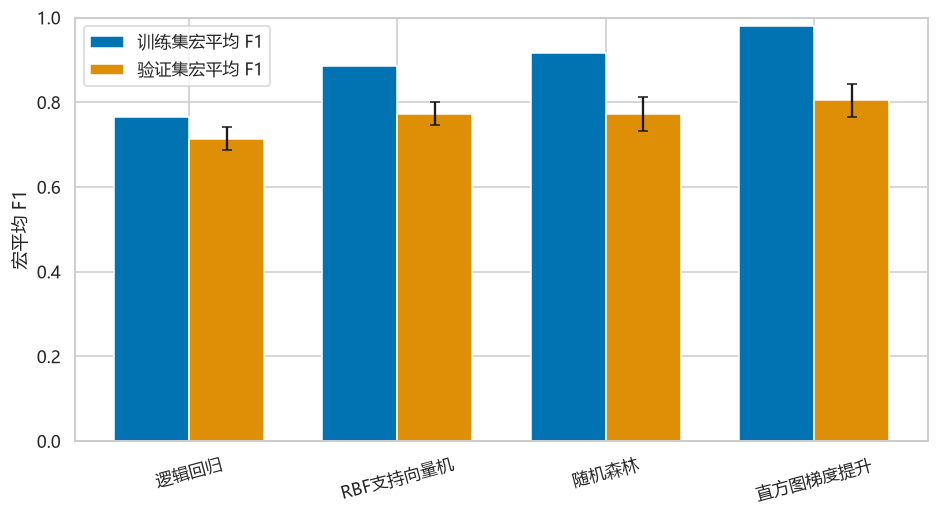

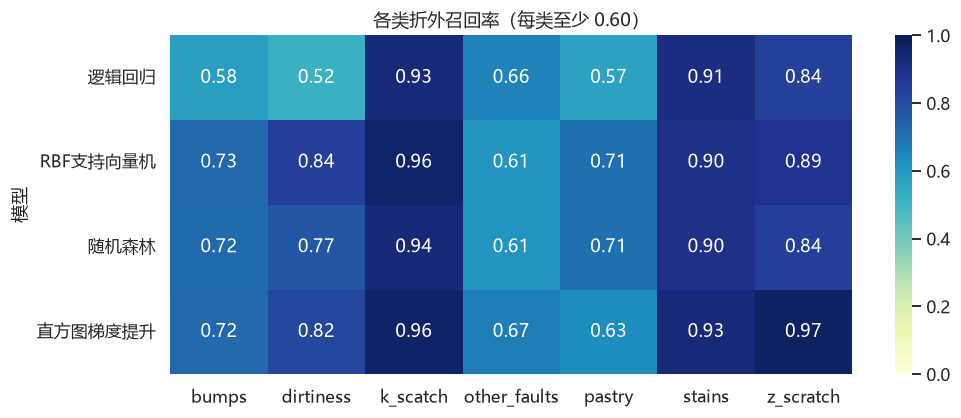

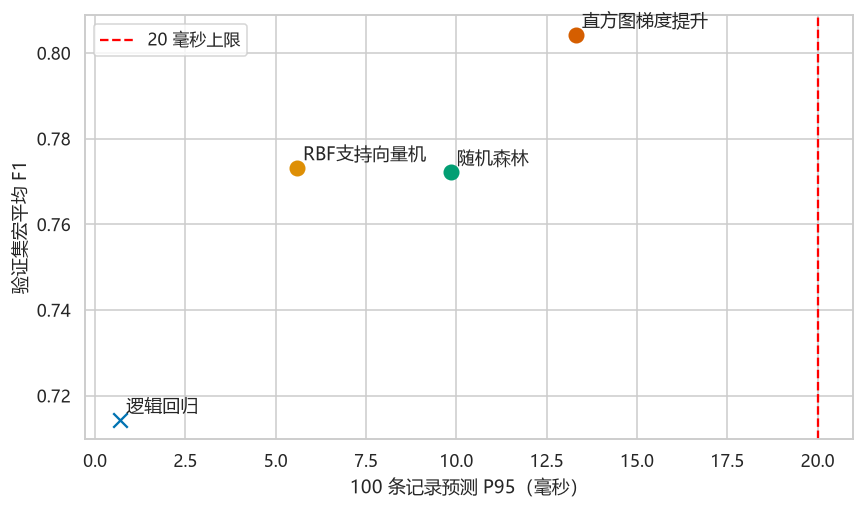

In [7]:
fig,ax=plt.subplots(figsize=(10,5))
positions=np.arange(len(comparison))
ax.bar(positions-.18,comparison.train_macro_f1,.36,label='Training macro F1')
ax.bar(positions+.18,comparison.validation_macro_f1,.36,yerr=comparison.validation_macro_f1_std,capsize=3,label='Validation macro F1')
ax.set(xticks=positions,xticklabels=comparison.family,ylim=(0,1),ylabel='Macro F1')
ax.tick_params(axis='x',rotation=15)
ax.legend()
figure(fig,'04_train_validation_f1.png')
recalls=comparison.set_index('family')[[f'oof_recall_{c}' for c in classes]]
recalls.columns=classes
fig,ax=plt.subplots(figsize=(10,4))
sns.heatmap(recalls,annot=True,fmt='.2f',vmin=0,vmax=1,cmap='YlGnBu',ax=ax)
ax.set_title('Out-of-fold class recall (constraint: every class >= 0.60)')
figure(fig,'05_oof_class_recall.png')
fig,ax=plt.subplots(figsize=(9,5))
for _,r in comparison.iterrows():
    ax.scatter(r.prediction_p95_ms,r.validation_macro_f1,s=90,marker='o' if r.feasible else 'x')
    ax.annotate(r.family,(r.prediction_p95_ms,r.validation_macro_f1),xytext=(4,5),textcoords='offset points')
ax.axvline(LATENCY_LIMIT_MS,color='red',linestyle='--',label='20 ms limit')
ax.set(xlabel='100-row prediction P95 (ms)',ylabel='Validation macro F1')
ax.legend()
figure(fig,'06_quality_latency_tradeoff.png')

## 6. 训练规模与资源

从开发集另留 20% 作内部验证，比较数据池中 25%、50%、75%、100% 的嵌套子集，重复五次。该验证集参与过调参，学习曲线只作诊断。完整拟合计时重复五次；模型体积按 joblib 文件记录。RSS 约每 1 ms 采样，可能漏掉瞬时峰值。

学习曲线重复 1 / 5


学习曲线重复 2 / 5


学习曲线重复 3 / 5


学习曲线重复 4 / 5


学习曲线重复 5 / 5


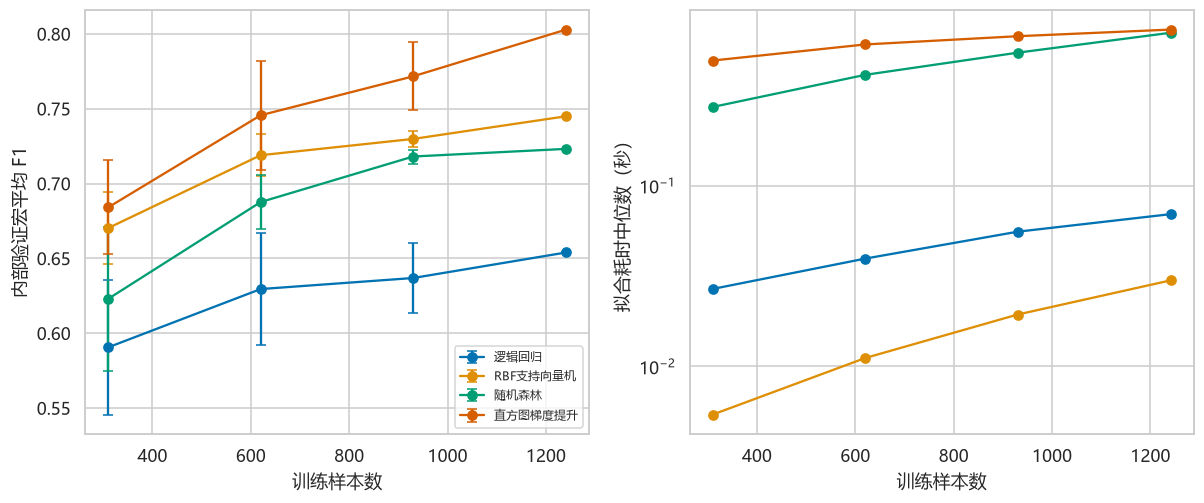

In [8]:
pool_X,learning_X,pool_y,learning_y=train_test_split(X_train,y_train,test_size=.2,stratify=y_train,random_state=SEED)
fractions=[.25,.5,.75,1.0]
subset_records=[]
learning_rows=[]
for repeat in range(5):
    nested={1.0:np.arange(len(pool_X))}
    current=nested[1.0]
    for fraction in [.75,.5,.25]:
        size=int(np.floor(len(pool_X)*fraction))
        chosen,_=train_test_split(current,train_size=size,stratify=pool_y.iloc[current],random_state=SEED+repeat)
        nested[fraction]=np.sort(chosen)
        current=nested[fraction]
    for fraction in fractions:
        idx=nested[fraction]
        subset_records.extend({'repeat':repeat+1,'fraction':fraction,'row_id':int(r)} for r in pool_X.iloc[idx].index)
        for _,r in comparison.iterrows():
            pipe=make_pipeline(r.family,params_by_id[r.candidate_id])
            with threadpool_limits(limits=1):
                t=perf_counter()
                pipe.fit(pool_X.iloc[idx],pool_y.iloc[idx])
                seconds=perf_counter()-t
                check_preprocessing(pipe,pool_X.iloc[idx])
                tr_pred=pipe.predict(pool_X.iloc[idx])
                va_pred=pipe.predict(learning_X)
            learning_rows.append({'family':r.family,'repeat':repeat+1,'fraction':fraction,'train_rows':len(idx),
                'train_macro_f1':f1_score(pool_y.iloc[idx],tr_pred,average='macro'),
                'validation_macro_f1':f1_score(learning_y,va_pred,average='macro'),'fit_seconds':seconds})
    print('Learning curves repeat',repeat+1,'/ 5',flush=True)
    save_table(pd.DataFrame(learning_rows),'learning_curve_raw.csv')
save_table(pd.DataFrame(subset_records),'learning_subsets.csv')
save_table(pd.DataFrame({'row_id':learning_X.index}),'learning_validation_rows.csv')
learning=pd.DataFrame(learning_rows)
fig,axes=plt.subplots(1,2,figsize=(13,5))
for family in grids:
    group=learning[learning.family==family].groupby('train_rows')
    means=group[['validation_macro_f1','fit_seconds']].mean()
    sd=group.validation_macro_f1.std().fillna(0)
    axes[0].errorbar(means.index,means.validation_macro_f1,yerr=sd,marker='o',capsize=3,label=family)
    axes[1].plot(means.index,group.fit_seconds.median(),marker='o',label=family)
axes[0].set(xlabel='Training rows',ylabel='Internal validation macro F1')
axes[1].set(xlabel='Training rows',ylabel='Median fit time (seconds)',yscale='log')
axes[0].legend(fontsize=8)
figure(fig,'07_learning_and_scaling.png')

In [9]:
MEMORY_WORKER = '''import os,sys,json
os.environ['OMP_NUM_THREADS']='1'
os.environ['OPENBLAS_NUM_THREADS']='1'
os.environ['MKL_NUM_THREADS']='1'
import joblib,psutil
from threadpoolctl import threadpool_limits
pipe,X,y=joblib.load(sys.argv[1])
process=psutil.Process()
base=process.memory_info().rss
print(json.dumps({'baseline_rss':base}),flush=True)
sys.stdin.readline()
with threadpool_limits(limits=1):
    pipe.fit(X,y)
print(json.dumps({'finished_rss':process.memory_info().rss}),flush=True)
sys.stdin.readline()
'''

def sample_fit_memory(template,name):
    payload=RUN_DIR / f'_memory_input_{name}.joblib'
    joblib.dump((template,X_train,y_train),payload)
    child=subprocess.Popen([sys.executable,'-u','-c',MEMORY_WORKER,str(payload)],
        stdin=subprocess.PIPE,stdout=subprocess.PIPE,stderr=subprocess.PIPE,text=True)
    baseline_line=child.stdout.readline()
    if not baseline_line:
        error=child.stderr.read()
        child.wait()
        raise RuntimeError('Memory worker failed: '+error)
    baseline=json.loads(baseline_line)['baseline_rss']
    process=psutil.Process(child.pid)
    child.stdin.write('fit\n');child.stdin.flush()
    # 拟合时采样内存。
    import threading
    completed=[]
    reader=threading.Thread(target=lambda:completed.append(child.stdout.readline()),daemon=True)
    reader.start()
    samples=[baseline]
    deadline=perf_counter()+180
    while reader.is_alive():
        if perf_counter()>deadline:
            child.kill();child.wait();payload.unlink(missing_ok=True)
            raise TimeoutError('Memory fit exceeded 180 seconds')
        try: samples.append(process.memory_info().rss)
        except psutil.NoSuchProcess: break
        sleep(.001)
    reader.join()
    result=json.loads(completed[0]) if completed and completed[0] else {}
    if 'finished_rss' in result: samples.append(result['finished_rss'])
    if child.poll() is None:
        child.stdin.write('exit\n');child.stdin.flush()
    _,stderr=child.communicate(timeout=20)
    payload.unlink(missing_ok=True)
    if child.returncode or not result: raise RuntimeError('Memory worker: '+stderr)
    return {'baseline_rss_mib':baseline/1024**2,'sampled_peak_process_rss_mib':max(samples)/1024**2,
        'sampled_peak_fit_increment_mib':(max(samples)-baseline)/1024**2,'rss_samples':len(samples)}

cost_rows=[]
fit_raw=[]
final_model=None
for _,r in comparison.iterrows():
    family=r.family
    fit_times=[]
    for repeat in range(FIT_REPEATS):
        pipe=make_pipeline(family,params_by_id[r.candidate_id])
        with threadpool_limits(limits=1):
            t=perf_counter();pipe.fit(X_train,y_train);elapsed=perf_counter()-t
            check_preprocessing(pipe,X_train)
        fit_times.append(elapsed)
        fit_raw.append({'family':family,'repeat':repeat+1,'fit_seconds':elapsed})
        if repeat==0:
            frozen=pipe
            if family==selected_family: final_model=pipe
    model_path=RUN_DIR / f'{family}.joblib'
    joblib.dump(frozen,model_path)
    memory=sample_fit_memory(make_pipeline(family,params_by_id[r.candidate_id]),family)
    cost_rows.append({'family':family,'candidate_id':r.candidate_id,
        'fit_median_seconds':float(np.median(fit_times)),
        'fit_q25_seconds':float(np.quantile(fit_times,.25)),'fit_q75_seconds':float(np.quantile(fit_times,.75)),
        'prediction_median_ms':r.prediction_median_ms,'prediction_p95_ms':r.prediction_p95_ms,
        'serialized_model_kib':model_path.stat().st_size/1024,**memory})
    print('Cost measurement complete:',family,flush=True)
    save_table(pd.DataFrame(cost_rows),'resource_comparison.csv')
    save_table(pd.DataFrame(fit_raw),'fit_timing_raw.csv')
assert final_model is not None
resource_comparison=pd.DataFrame(cost_rows)
display(resource_comparison)

资源测量完成： 逻辑回归


资源测量完成： RBF支持向量机


资源测量完成： 随机森林


资源测量完成： 直方图梯度提升


,模型,配置编号,拟合中位数秒,拟合耗时下四分位数秒,拟合耗时上四分位数秒,预测中位数毫秒,预测P95毫秒,模型体积KiB,基线RSS内存MiB,采样进程峰值RSS内存MiB,采样拟合内存增量MiB,RSS采样次数
0,逻辑回归,LogisticRegression_09,0.0730,0.0715,0.0732,0.6255,0.6934,4.8135,138.8398,141.3008,2.4609,82
1,RBF支持向量机,RBF_SVC_11,0.0430,0.0429,0.0430,5.0406,5.5863,287.2471,138.6445,142.2227,3.5781,65
2,随机森林,RandomForest_12,0.8958,0.8878,0.9027,9.1664,9.8450,8389.0254,141.6680,152.6133,10.9453,576
3,直方图梯度提升,HistGradientBoosting_07,0.8162,0.8136,0.8240,13.0398,13.3083,1316.4150,141.6719,146.5273,4.8555,525


In [10]:
# 仅检查开发阶段。
BASE_RUN_DIR=RUN_DIR
assert len(candidate_rows)+len(fit_failures)==48
assert len(fold_rows)==5*len(candidate_rows)
assert set(comparison.candidate_id)==set(FROZEN_BASE_REPS.values())
assert not (RUN_DIR/'test_predictions.csv').exists()
save_json({'development_completed':True,'test_evaluations':0,'representative_policy':'historical replay'},'COMPLETED.json')
(PROJECT/'results/latest_run.txt').write_text(RUN_DIR.name,encoding='utf8')
print('Part A verified; no holdout predictions:', BASE_RUN_DIR)


A 部分检查通过，尚未预测留出集： .\base\results\20261115_170610_319599


## B 部分 支持向量机补充实验

线性核与 RBF 核使用相同开发样本和折划分。支持向量机的搜索范围更大，与其他模型的搜索预算不同。

In [11]:
from pathlib import Path
from datetime import datetime, timezone
from time import perf_counter, sleep
import hashlib
import importlib.metadata
import json
import platform
import sys
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display as _display
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report,
    f1_score, precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import ParameterGrid, ParameterSampler, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from threadpoolctl import threadpool_limits, threadpool_info

ROOT=INTEGRATED_ROOT/'supplement'
ORIGINAL=BASE_RUN_DIR
DATA=INTEGRATED_ROOT/'data'/'steel-plates-faults.csv'
EXPECTED='9e9bfebd2ea8bf84f5264325fadace2194387991183cb20d52075ef72e2c858e'
RUN=ROOT/'results'/datetime.now().strftime('%Y%m%d_%H%M%S_%f')
FIG=RUN/'figures'
FIG.mkdir(parents=True,exist_ok=False)
SEED=0
MIN_RECALL=.60
LATENCY_LIMIT=20.0
TIMING_ROUNDS=5
TIMING_REPEATS=100
BATCH_SIZE=100
PERMUTATION_REPEATS=5
warnings.filterwarnings('error',category=ConvergenceWarning)
sns.set_theme(style='whitegrid',palette='colorblind')
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':160})
plt.rcParams['font.sans-serif']=[CW2_FONT]
pd.set_option('display.max_columns',18)

def json_default(x):
    if isinstance(x,Path): return str(x)
    if isinstance(x,np.generic): return x.item()
    if isinstance(x,np.ndarray): return x.tolist()
    raise TypeError(type(x).__name__)

def save_json(value,name):
    (RUN/name).write_text(json.dumps(value,ensure_ascii=False,indent=2,
        default=json_default,allow_nan=False),encoding='utf-8')

def table(frame,name,index=False):
    frame.to_csv(RUN/name,index=index,encoding='utf-8-sig')

def figure(fig,name):
    localize_figure(fig)
    fig.savefig(FIG/name,bbox_inches='tight')
    plt.show()
    plt.close(fig)

def canonical(params):
    # 去除重复配置。
    normal={k:(float(v) if isinstance(v,(int,float,np.number)) and not isinstance(v,(bool,np.bool_)) else v)
            for k,v in params.items()}
    return json.dumps(normal,sort_keys=True)

save_json({'python':sys.version,'executable':sys.executable,'platform':platform.platform(),
    'versions':{p:importlib.metadata.version(p) for p in ['scikit-learn','numpy','pandas','matplotlib','joblib','nbclient']},
    'initial_threadpools':threadpool_info(),'thread_policy':'All fit/predict operations limited to one BLAS/OpenMP thread; RF n_jobs=1'},'environment.json')
save_json({'original_run':ORIGINAL,'seed':SEED,'folds':5,'test_evaluations':0,
    'min_recall':MIN_RECALL,'latency_limit_ms':LATENCY_LIMIT,'batch_rows':BATCH_SIZE,
    'timing_rounds':TIMING_ROUNDS,'calls_per_round':TIMING_REPEATS,
    'stable_rule':'every one of the five round P95 values <= 20 ms',
    'search':'coarse 14 linear + 24 sampled RBF + original RBF anchor, then local refinement',
    'refinement_factors':[1/3,1,3],'permutation_repeats':PERMUTATION_REPEATS,
    'adaptive_search_optimism':True,'new_independent_test_evidence':False},'protocol_locked.json')
print('Supplement run:',RUN)

补充实验目录： .\supplement\results\20261115_170952_841582


## 1. 开发集与预处理

复用 A 部分的样本和折编号。中位数与标准化统计量只从当前训练折学习。留出样本不参与搜索。

In [12]:
assert hashlib.sha256(DATA.read_bytes()).hexdigest()==EXPECTED
raw=pd.read_csv(DATA)
membership=pd.read_csv(ORIGINAL/'split_membership.csv')
training_ids=set(membership.loc[membership.split=='train','row_id'])
excluded_ids=set(membership.loc[membership.split=='test','row_id'])
# 保留原训练顺序。
train_order=pd.read_csv(ORIGINAL/'oof_predictions.csv',usecols=['row_id'],nrows=1552).row_id.to_numpy()
assert set(train_order)==training_ids
development=raw.iloc[train_order].copy()
del raw
X=development.drop(columns='fault_type')
y=development.fault_type
classes=sorted(y.unique())
assert len(X)==1552 and not training_ids&excluded_ids
folds=list(StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED).split(X,y))
fold_ids=np.zeros(len(X),dtype=int)
for k,(fit,val) in enumerate(folds,1): fold_ids[val]=k
original_folds=pd.read_csv(ORIGINAL/'cv_fold_membership.csv').set_index('row_id').validation_fold
assert np.array_equal(fold_ids,original_folds.loc[X.index].to_numpy())
table(pd.DataFrame({'row_id':X.index,'validation_fold':fold_ids}),'development_membership.csv')
old_comparison=pd.read_csv(ORIGINAL/'model_comparison.csv')

def make_pipe(family,params):
    if family in ('SVM','linear','rbf'):
        model=SVC(probability=False,decision_function_shape='ovr',max_iter=100000,**params)
    elif family=='LogisticRegression':
        model=LogisticRegression(penalty='l2',solver='lbfgs',max_iter=5000,random_state=SEED,**params)
    elif family=='RandomForest':
        model=RandomForestClassifier(n_estimators=300,max_features='sqrt',n_jobs=1,random_state=SEED,**params)
    elif family=='HistGradientBoosting':
        model=HistGradientBoostingClassifier(max_iter=200,min_samples_leaf=10,l2_regularization=1,
            early_stopping=False,random_state=SEED,**params)
    else: raise ValueError(family)
    steps=[('imputer',SimpleImputer(strategy='median'))]
    if family not in ('RandomForest','HistGradientBoosting'): steps.append(('scaler',StandardScaler()))
    return Pipeline(steps+[('model',model)])

def check_preprocessing(pipe,train):
    np.testing.assert_allclose(pipe['imputer'].statistics_,train.median().to_numpy())
    if 'scaler' in pipe.named_steps:
        np.testing.assert_allclose(pipe['scaler'].mean_,pipe['imputer'].transform(train).mean(axis=0),rtol=1e-9,atol=1e-9)
        assert np.all(np.asarray(pipe['scaler'].n_samples_seen_)==len(train))

def recalls(truth,pred):
    report=classification_report(truth,pred,labels=classes,output_dict=True,zero_division=0)
    return {c:float(report[c]['recall']) for c in classes}

## 2. 两阶段搜索

线性核比较七个 C 值和两种类别权重；RBF 在同一对数范围固定抽取 24 个配置，并加入原配置。随后以 1/3、1、3 倍进行局部细化并去重。共尝试 59 个配置：53 个完成，六个线性配置未收敛。复用相同折进行细化可能使选型分数偏乐观。

便携版按参数定位原有 SVM 代表配置；若局部细化结果不同，会确保两组固定参考参数存在，并继续去重。

In [13]:
C_GRID=[.001,.01,.1,1,10,100,1000]
GAMMA_GRID=[.001,.01,.1,1,10,100,1000]
coarse=list(ParameterGrid({'kernel':['linear'],'C':C_GRID,'class_weight':[None,'balanced']}))
coarse+=list(ParameterSampler({'kernel':['rbf'],'C':C_GRID,'gamma':GAMMA_GRID,
    'class_weight':[None,'balanced']},n_iter=24,random_state=SEED))
coarse.append({'kernel':'rbf','C':10,'gamma':'scale','class_weight':'balanced'})
save_json({'linear_C':C_GRID,'rbf_C':C_GRID,'rbf_gamma':GAMMA_GRID,
    'coarse_params':coarse,'rbf_sampler_seed':SEED,'svc_max_iter':100000,
    'convergence_policy':'record a failed candidate, never score partial convergence',
    'refinement_factors':[1/3,1,3]},'search_space.json')
rows=[]
fold_rows=[]
oof_frames=[]
failures=[]
seen_params=set()
params_by_id={}
search_start=perf_counter()

def evaluate_candidates(param_list,stage):
    for params in param_list:
        key=canonical(params)
        if key in seen_params: continue
        seen_params.add(key)
        cid=f'SVM_{len(params_by_id)+1:03d}'
        params_by_id[cid]=params
        local=[]
        prediction=np.empty(len(X),dtype=object)
        seen=np.zeros(len(X),dtype=int)
        start=perf_counter()
        try:
            for fold,(fit,val) in enumerate(folds,1):
                pipe=make_pipe('SVM',params)
                with threadpool_limits(limits=1):
                    t=perf_counter();pipe.fit(X.iloc[fit],y.iloc[fit]);seconds=perf_counter()-t
                    check_preprocessing(pipe,X.iloc[fit])
                    train_pred=pipe.predict(X.iloc[fit])
                    val_pred=pipe.predict(X.iloc[val])
                prediction[val]=val_pred
                seen[val]+=1
                local.append({'candidate_id':cid,'stage':stage,'kernel':params['kernel'],'fold':fold,
                    'train_macro_f1':f1_score(y.iloc[fit],train_pred,average='macro'),
                    'validation_macro_f1':f1_score(y.iloc[val],val_pred,average='macro'),
                    'validation_accuracy':accuracy_score(y.iloc[val],val_pred),'fit_seconds':seconds})
            assert np.all(seen==1)
            rec=recalls(y,prediction)
            val_mean=float(np.mean([r['validation_macro_f1'] for r in local]))
            train_mean=float(np.mean([r['train_macro_f1'] for r in local]))
            row={'candidate_id':cid,'stage':stage,'kernel':params['kernel'],'params':key,
                'train_macro_f1':train_mean,'validation_macro_f1':val_mean,
                'validation_macro_f1_std':float(np.std([r['validation_macro_f1'] for r in local],ddof=1)),
                'train_validation_gap':train_mean-val_mean,'oof_macro_f1':f1_score(y,prediction,average='macro'),
                'oof_min_class_recall':min(rec.values()),'quality_pass':min(rec.values())>=MIN_RECALL,
                'candidate_wall_seconds':perf_counter()-start,'mean_fold_fit_seconds':float(np.mean([r['fit_seconds'] for r in local]))}
            row.update({'oof_recall_'+c:v for c,v in rec.items()})
            rows.append(row);fold_rows.extend(local)
            oof_frames.append(pd.DataFrame({'candidate_id':cid,'row_id':X.index,'fold':fold_ids,
                'truth':y.to_numpy(),'prediction':prediction}))
            print(f'{stage} {cid} {params["kernel"]}: F1={val_mean:.4f}, min recall={min(rec.values()):.3f}',flush=True)
        except Exception as exc:
            failures.append({'candidate_id':cid,'params':params,'type':type(exc).__name__,'error':str(exc)})
            print('FAILED',cid,exc,flush=True)
        table(pd.DataFrame(rows),'svm_candidates.csv')
        table(pd.DataFrame(fold_rows),'svm_folds.csv')
        if oof_frames: table(pd.concat(oof_frames,ignore_index=True),'svm_oof_predictions.csv')
        save_json(failures,'fit_failures.json')
        save_json(params_by_id,'candidate_registry.json')

evaluate_candidates(coarse,'coarse')
coarse_results=pd.DataFrame(rows)
refined=[]
centers=[]
for kernel in ['linear','rbf']:
    best=coarse_results[coarse_results.kernel==kernel].sort_values(['validation_macro_f1','candidate_id'],ascending=[False,True]).iloc[0]
    center=params_by_id[best.candidate_id]
    centers.append({'kernel':kernel,'candidate_id':best.candidate_id,'params':center})
    grid={'kernel':[kernel],'C':[float(center['C']*a) for a in [1/3,1,3]],'class_weight':[None,'balanced']}
    if kernel=='rbf':
        gamma=1/X.shape[1] if center['gamma']=='scale' else center['gamma']
        grid['gamma']=[float(gamma*a) for a in [1/3,1,3]]
    refined+=list(ParameterGrid(grid))
refined.extend(FROZEN_KERNEL_PARAMS.values())
save_json({'coarse_centers':centers,'refinement_params':refined},'refinement_locked.json')
evaluate_candidates(refined,'refinement')
svm_results=pd.DataFrame(rows)
save_json({'wall_seconds_including_checkpoint_io':perf_counter()-search_start,
    'attempted':len(params_by_id),'complete':len(rows),'failed':len(failures)},'search_cost.json')
display(svm_results.sort_values('validation_macro_f1',ascending=False).head(12))

粗搜索 SVM_001 线性核: F1=0.2073, 最低召回率=0.000


粗搜索 SVM_002 线性核: F1=0.5109, 最低召回率=0.113


粗搜索 SVM_003 线性核: F1=0.5424, 最低召回率=0.000


粗搜索 SVM_004 线性核: F1=0.6565, 最低召回率=0.392


粗搜索 SVM_005 线性核: F1=0.7165, 最低召回率=0.409


粗搜索 SVM_006 线性核: F1=0.6960, 最低召回率=0.444


... (51 outputs left out)

局部细化 SVM_057 RBF核: F1=0.7455, 最低召回率=0.528


局部细化 SVM_058 RBF核: F1=0.7630, 最低召回率=0.597


局部细化 SVM_059 RBF核: F1=0.7446, 最低召回率=0.484


,配置编号,搜索阶段,核函数,参数,训练集宏平均F1,验证集宏平均F1,验证F1折间标准差,训练验证差距,折外宏平均F1,...,配置总耗时秒,平均每折拟合秒数,折外召回率_bumps,折外召回率_dirtiness,折外召回率_k_scatch,折外召回率_other_faults,折外召回率_pastry,折外召回率_stains,折外召回率_z_scratch
39,SVM_046,局部细化,RBF核,"{""C"": 33.33333333333333, ""class_weight"": null,...",0.9483,0.7749,0.0316,0.1734,0.7758,...,0.5245,0.0353,0.6947,0.7955,0.9617,0.6784,0.5556,0.8966,0.8355
42,SVM_049,局部细化,RBF核,"{""C"": 33.33333333333333, ""class_weight"": ""bala...",0.9177,0.7741,0.0169,0.1436,0.7741,...,0.4961,0.0325,0.7290,0.8409,0.9617,0.6134,0.6270,0.8966,0.8882
20,SVM_027,粗搜索,RBF核,"{""C"": 100.0, ""class_weight"": null, ""gamma"": 0....",0.8968,0.7737,0.0287,0.1232,0.7742,...,0.5151,0.0391,0.6885,0.7273,0.9553,0.6896,0.5556,0.8966,0.8553
32,SVM_039,粗搜索,RBF核,"{""C"": 10.0, ""class_weight"": ""balanced"", ""gamma...",0.8853,0.7732,0.0267,0.1121,0.7722,...,0.5183,0.0327,0.7259,0.8409,0.9585,0.6059,0.7063,0.8966,0.8882
38,SVM_045,局部细化,RBF核,"{""C"": 33.33333333333333, ""class_weight"": null,...",0.8569,0.7689,0.0205,0.0880,0.7696,...,0.5016,0.0322,0.6698,0.6591,0.9489,0.6859,0.5556,0.9138,0.8487
47,SVM_054,局部细化,RBF核,"{""C"": 300.0, ""class_weight"": null, ""gamma"": 0....",0.8601,0.7658,0.0334,0.0943,0.7664,...,0.5459,0.0445,0.6698,0.6818,0.9521,0.6840,0.5476,0.9138,0.8618
43,SVM_050,局部细化,RBF核,"{""C"": 100.0, ""class_weight"": null, ""gamma"": 0....",0.8264,0.7653,0.0296,0.0610,0.7659,...,0.5130,0.0338,0.6480,0.6364,0.9457,0.7026,0.5794,0.9138,0.8421
51,SVM_058,局部细化,RBF核,"{""C"": 300.0, ""class_weight"": ""balanced"", ""gamm...",0.9148,0.7630,0.0254,0.1518,0.7629,...,0.5685,0.0495,0.7227,0.8182,0.9585,0.5967,0.6190,0.8966,0.8684
15,SVM_022,粗搜索,RBF核,"{""C"": 100.0, ""class_weight"": ""balanced"", ""gamm...",0.8766,0.7619,0.0347,0.1147,0.7609,...,0.4992,0.0363,0.7165,0.8182,0.9585,0.5743,0.7302,0.9138,0.8947
48,SVM_055,局部细化,RBF核,"{""C"": 300.0, ""class_weight"": null, ""gamma"": 0....",0.9436,0.7596,0.0345,0.1840,0.7599,...,0.6266,0.0596,0.6760,0.7727,0.9585,0.6524,0.5635,0.8793,0.8289


## B3 重复计时

每个代表配置测量五轮。每轮预热五次，再计时调用 100 次，每次预测相同的 100 条开发样本。耗时包含预处理。自动排序仅作描述，冻结的工程选择仍为支持向量机。

In [14]:
batch_ids=pd.read_csv(ORIGINAL/'latency_batch_rows.csv').row_id.to_numpy()
batch=X.loc[batch_ids]
assert len(batch)==100 and set(batch_ids)<=training_ids
table(pd.DataFrame({'row_id':batch_ids}),'latency_batch_rows.csv')
latency_rows=[]
latency_checks=[]
timed_models={}

def timing_measure(pipe,cid,family):
    all_values=[]
    p95s=[]
    with threadpool_limits(limits=1):
        for round_id in range(1,TIMING_ROUNDS+1):
            for _ in range(5): pipe.predict(batch)
            values=[]
            for repeat in range(1,TIMING_REPEATS+1):
                t=perf_counter();pipe.predict(batch);ms=(perf_counter()-t)*1000
                values.append(ms)
                latency_rows.append({'family':family,'candidate_id':cid,'round':round_id,'repeat':repeat,'predict_100_ms':ms})
            p95s.append(float(np.quantile(values,.95)))
            all_values.extend(values)
            sleep(.05)
    return {'prediction_median_ms':float(np.median(all_values)),
        'pooled_p95_ms':float(np.quantile(all_values,.95)),
        'worst_round_p95_ms':max(p95s),'round_p95_values':json.dumps(p95s),
        'timing_rounds_passed':sum(v<=LATENCY_LIMIT for v in p95s),
        'stable_latency_pass':all(v<=LATENCY_LIMIT for v in p95s)}

def measure_candidate(row,family,params):
    cid=row['candidate_id']
    pipe=make_pipe(family,params)
    with threadpool_limits(limits=1):
        pipe.fit(X,y);check_preprocessing(pipe,X)
    measured=dict(row)
    measured.update(timing_measure(pipe,cid,family))
    measured['family']=family
    measured['quality_pass']=bool(row['oof_min_class_recall']>=MIN_RECALL)
    measured['stable_feasible']=bool(measured['quality_pass'] and measured['stable_latency_pass'])
    measured['violation']=float(max(0,MIN_RECALL-row['oof_min_class_recall'])+max(0,measured['worst_round_p95_ms']/LATENCY_LIMIT-1))
    latency_checks.append(measured)
    timed_models[cid]=pipe
    table(pd.DataFrame(latency_checks),'stability_candidate_checks.csv')
    table(pd.DataFrame(latency_rows),'latency_rounds_raw.csv')
    print(cid,'five round P95:',measured['round_p95_values'],'feasible:',measured['stable_feasible'],flush=True)
    return measured

def choose_reference(records):
    feasible=[r for r in records if r['stable_feasible']]
    if feasible:
        return sorted(feasible,key=lambda r:(-r['validation_macro_f1'],r['worst_round_p95_ms'],r['candidate_id']))[0]
    return sorted(records,key=lambda r:(r['violation'],-r['validation_macro_f1'],r['candidate_id']))[0]

kernel_winners=[]
for kernel in ['linear','rbf']:
    pool=svm_results[svm_results.kernel==kernel].copy()
    pool['recall_deficit']=(MIN_RECALL-pool.oof_min_class_recall).clip(lower=0)
    ordered=pool.loc[pool.params.eq(canonical(FROZEN_KERNEL_PARAMS[kernel]))].copy()
    assert len(ordered)==1
    checked=[]
    for _,row in ordered.iterrows():
        result=measure_candidate(row.to_dict(),'SVM',params_by_id[row.candidate_id])
        checked.append(result)
        # 测量保留配置的耗时。
        if result['stable_latency_pass']:break
    kernel_winners.append(choose_reference(checked))
table(pd.DataFrame(kernel_winners),'linear_rbf_comparison.csv')
svm_winner=next(r for r in kernel_winners if r['kernel']=='rbf')
assert params_by_id[svm_winner['candidate_id']]==FROZEN_DECISION['params']
representatives=[svm_winner]
representative_params={'SVM':params_by_id[svm_winner['candidate_id']]}
for _,old in old_comparison[old_comparison.family!='RBF_SVC'].iterrows():
    family=old.family
    params=json.loads(old.params)
    representative_params[family]=params
    representatives.append(measure_candidate(old.to_dict(),family,params))
comparison=pd.DataFrame(representatives)
table(comparison,'updated_model_comparison.csv')
selected=choose_reference(representatives)
save_json({'family':selected['family'],'candidate_id':selected['candidate_id'],
    'params':representative_params[selected['family']],
    'status':'stable_development_constraints_met' if selected['stable_feasible'] else 'no_stably_feasible_model_closest_reference',
    'validation_macro_f1':selected['validation_macro_f1'],'worst_round_p95_ms':selected['worst_round_p95_ms'],
    'test_evaluations':0,'independent_test_performance':'not_estimated',
    'locked_at_utc':datetime.now(timezone.utc).isoformat()},'updated_recommendation.json')
joblib.dump(timed_models[selected['candidate_id']],RUN/'development_recommended_pipeline.joblib')
display(comparison[['family','validation_macro_f1','oof_min_class_recall','worst_round_p95_ms','timing_rounds_passed','stable_feasible']])

SVM_042 五轮 P95： [2.125804998468084, 2.3162750021583633, 2.0407750009326264, 1.9840949988065404, 2.068160000817443] 开发约束通过： False


SVM_049 五轮 P95： [4.88226499837765, 4.797855001561402, 4.987270000310673, 5.243340001106844, 6.686464999074815] 开发约束通过： True


LogisticRegression_09 五轮 P95： [1.0840799999641604, 1.0055449987703469, 0.7757799983664881, 0.7304099992325064, 0.9116749994063866] 开发约束通过： False


RandomForest_12 五轮 P95： [12.419685002896584, 11.584805000529741, 10.53724999892438, 10.238640003080945, 9.925215001385368] 开发约束通过： True


HistGradientBoosting_07 五轮 P95： [14.32492999920214, 13.70534499801579, 13.983395000286691, 13.773615001264261, 13.849894999657408] 开发约束通过： True


,模型,验证集宏平均F1,最低类别折外召回率,最差轮P95毫秒,计时通过轮数,开发约束通过
0,支持向量机,0.7741,0.6134,6.6865,5,True
1,逻辑回归,0.7144,0.5227,1.0841,5,False
2,随机森林,0.7722,0.6097,12.4197,5,True
3,直方图梯度提升,0.8043,0.6349,14.3249,5,True


## B4 核函数与模型比较

比较代表配置的验证 F1、最低折外召回率和耗时。各模型的搜索预算不同。

梯度提升训练 F1 为 0.9813，验证 F1 为 0.8043，差距为 0.1770；支持向量机差距为 0.1436。两者均有过拟合表现。学习曲线使用开发数据，仅作诊断。

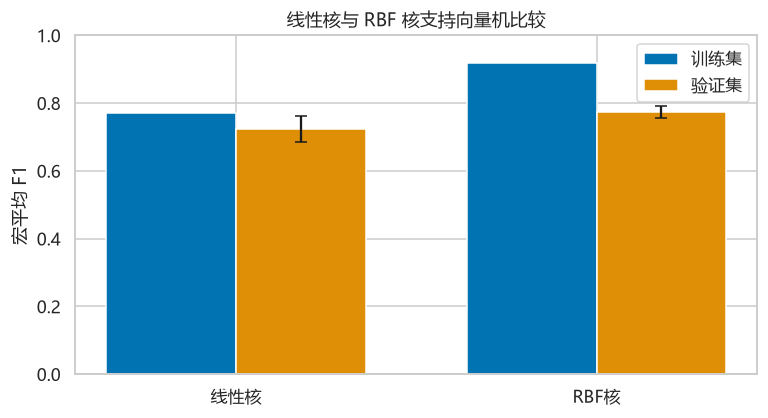

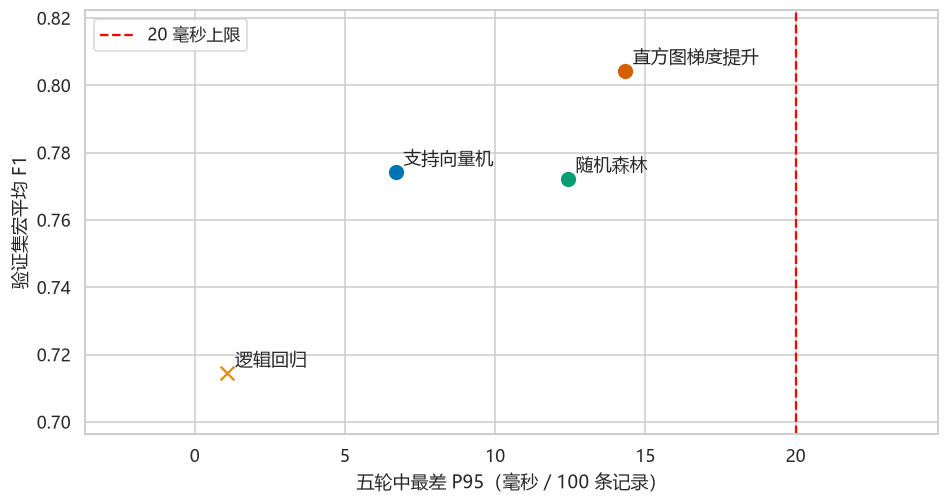

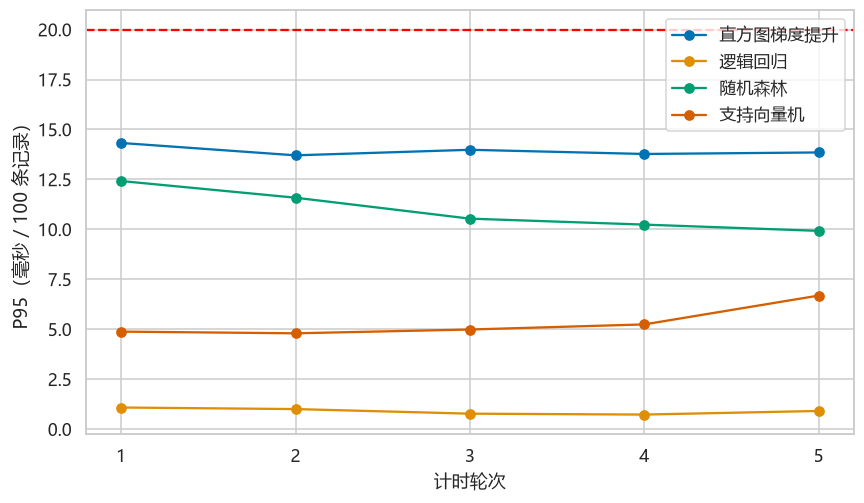

In [15]:
kw=pd.DataFrame(kernel_winners)
fig,ax=plt.subplots(figsize=(8,4))
pos=np.arange(2)
ax.bar(pos-.18,kw.train_macro_f1,.36,label='Training')
ax.bar(pos+.18,kw.validation_macro_f1,.36,yerr=kw.validation_macro_f1_std,capsize=4,label='Validation')
ax.set(xticks=pos,xticklabels=kw.kernel,ylabel='Macro F1',ylim=(0,1),title='Linear versus RBF SVM representatives')
ax.legend();figure(fig,'01_linear_rbf.png')
fig,ax=plt.subplots(figsize=(10,5))
for _,row in comparison.iterrows():
    ax.scatter(row.worst_round_p95_ms,row.validation_macro_f1,s=80,marker='o' if row.stable_feasible else 'x')
    ax.annotate(row.family,(row.worst_round_p95_ms,row.validation_macro_f1),xytext=(5,5),textcoords='offset points')
ax.axvline(20,color='red',linestyle='--',label='20 ms limit')
ax.margins(x=.25,y=.2)
ax.set(xlabel='Worst of five round P95 (ms / 100 rows)',ylabel='Validation macro F1')
ax.legend();figure(fig,'02_stable_quality_latency.png')
raw_timing=pd.DataFrame(latency_rows)
chosen_ids=comparison.candidate_id.tolist()
round_summary=raw_timing[raw_timing.candidate_id.isin(chosen_ids)].groupby(['family','candidate_id','round']).predict_100_ms.agg(
    median='median',p95=lambda a:np.quantile(a,.95)).reset_index()
table(round_summary,'representative_timing_rounds.csv')
fig,ax=plt.subplots(figsize=(9,5))
for family,group in round_summary.groupby('family'):
    ax.plot(group['round'],group.p95,marker='o',label=family)
ax.axhline(20,color='red',linestyle='--')
ax.set(xlabel='Timing round',ylabel='P95 (ms / 100 rows)',xticks=range(1,6))
ax.legend();figure(fig,'03_timing_stability.png')

## 5. ROC 与 PR

使用各验证折的 decision_function 分数，逐类计算 ROC 曲线下面积和平均精确率后取平均。分数不是概率；平均精确率不是梯形 PR 面积。SVC 内部按一对一方式训练。

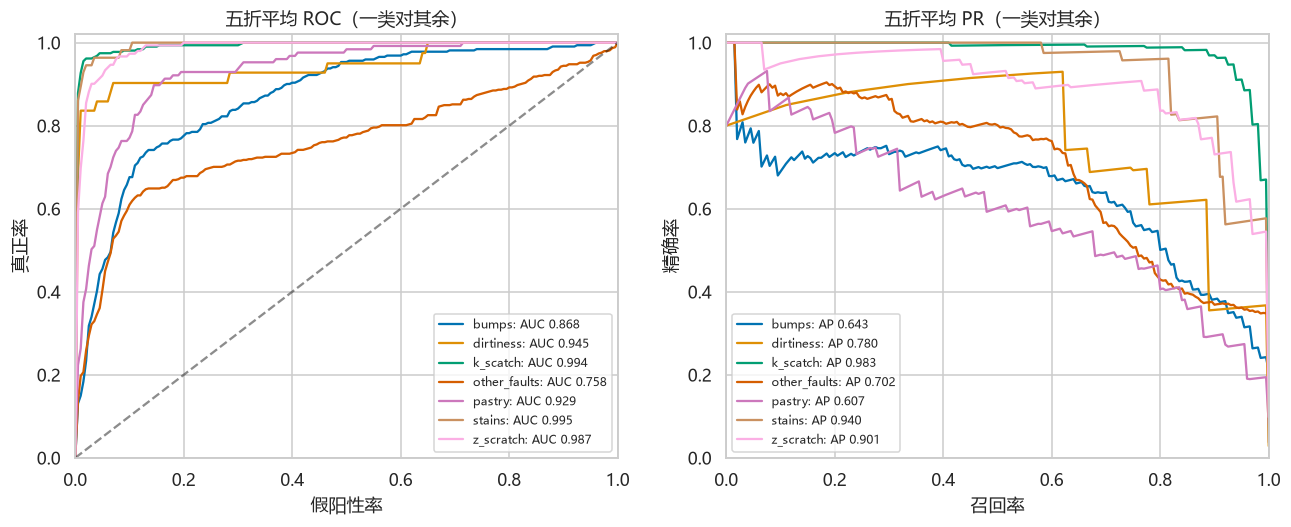

,ROC面积均值,ROC面积标准差,平均精确率均值,平均精确率标准差,类别比例
bumps,0.8679,0.0294,0.6434,0.1017,0.2068
dirtiness,0.9449,0.0833,0.7804,0.2266,0.0283
k_scatch,0.9941,0.0047,0.9825,0.0125,0.2017
other_faults,0.7581,0.0296,0.7022,0.0132,0.3466
pastry,0.9293,0.0235,0.6075,0.1234,0.0812
stains,0.9949,0.0051,0.9400,0.0410,0.0374
z_scratch,0.9871,0.0078,0.9007,0.0563,0.0979


In [16]:
curve_metrics=[]
score_frames=[]
roc_points=[]
pr_points=[]
roc_grid=np.linspace(0,1,201)
recall_grid=np.linspace(0,1,201)
svm_params=representative_params['SVM']
for fold,(fit,val) in enumerate(folds,1):
    pipe=make_pipe('SVM',svm_params)
    with threadpool_limits(limits=1):
        pipe.fit(X.iloc[fit],y.iloc[fit]);check_preprocessing(pipe,X.iloc[fit])
        scores=pipe.decision_function(X.iloc[val])
    assert list(pipe.classes_)==classes and scores.shape==(len(val),len(classes))
    sf=pd.DataFrame(scores,columns=classes)
    sf.insert(0,'row_id',X.index[val]);sf.insert(1,'fold',fold);sf.insert(2,'truth',y.iloc[val].to_numpy())
    score_frames.append(sf)
    for j,label in enumerate(classes):
        truth=(y.iloc[val].to_numpy()==label).astype(int)
        fpr,tpr,_=roc_curve(truth,scores[:,j])
        precision,recall,_=precision_recall_curve(truth,scores[:,j])
        interp_tpr=np.interp(roc_grid,fpr,tpr);interp_tpr[0]=0;interp_tpr[-1]=1
        interp_precision=np.interp(recall_grid,recall[::-1],precision[::-1])
        curve_metrics.append({'fold':fold,'class':label,'roc_auc':roc_auc_score(truth,scores[:,j]),
            'average_precision':average_precision_score(truth,scores[:,j]),'prevalence':float(truth.mean())})
        roc_points.extend({'fold':fold,'class':label,'fpr':float(x),'tpr':float(v)} for x,v in zip(roc_grid,interp_tpr))
        pr_points.extend({'fold':fold,'class':label,'recall':float(x),'precision':float(v)} for x,v in zip(recall_grid,interp_precision))
table(pd.concat(score_frames,ignore_index=True),'svm_validation_decision_scores.csv')
table(pd.DataFrame(curve_metrics),'svm_curve_metrics.csv')
table(pd.DataFrame(roc_points),'roc_interpolated.csv')
table(pd.DataFrame(pr_points),'pr_interpolated.csv')
curve_summary=pd.DataFrame(curve_metrics).groupby('class').agg(roc_auc_mean=('roc_auc','mean'),roc_auc_sd=('roc_auc','std'),
    ap_mean=('average_precision','mean'),ap_sd=('average_precision','std'),prevalence=('prevalence','mean'))
table(curve_summary.rename_axis('class').reset_index(),'svm_curve_summary.csv')
fig,axes=plt.subplots(1,2,figsize=(14,5))
for label in classes:
    rc=pd.DataFrame(roc_points).query('`class` == @label').groupby('fpr').tpr.mean()
    pr=pd.DataFrame(pr_points).query('`class` == @label').groupby('recall').precision.mean()
    axes[0].plot(rc.index,rc.values,label=f'{label}: AUC {curve_summary.loc[label,"roc_auc_mean"]:.3f}')
    axes[1].plot(pr.index,pr.values,label=f'{label}: AP {curve_summary.loc[label,"ap_mean"]:.3f}')
axes[0].plot([0,1],[0,1],'k--',alpha=.5)
axes[0].set(xlabel='False positive rate',ylabel='True positive rate',title='Mean fold ROC (one class versus rest)')
axes[1].set(xlabel='Recall',ylabel='Precision',title='Mean fold PR (one class versus rest)')
for ax in axes:ax.legend(fontsize=8);ax.set_xlim(0,1);ax.set_ylim(0,1.02)
figure(fig,'04_svm_roc_pr.png')
display(curve_summary)

## 6. 置换重要性

在五个验证折内逐特征打乱五次，记录宏平均 F1 的下降。相关特征可能互相替代；重要性不表示因果关系，也不用于重新筛选特征。

置换重要性： 支持向量机 折 1 /5


置换重要性： 支持向量机 折 2 /5


置换重要性： 支持向量机 折 3 /5


置换重要性： 支持向量机 折 4 /5


置换重要性： 支持向量机 折 5 /5


置换重要性： 逻辑回归 折 1 /5


... (10 outputs left out)

置换重要性： 直方图梯度提升 折 2 /5


置换重要性： 直方图梯度提升 折 3 /5


置换重要性： 直方图梯度提升 折 4 /5


置换重要性： 直方图梯度提升 折 5 /5


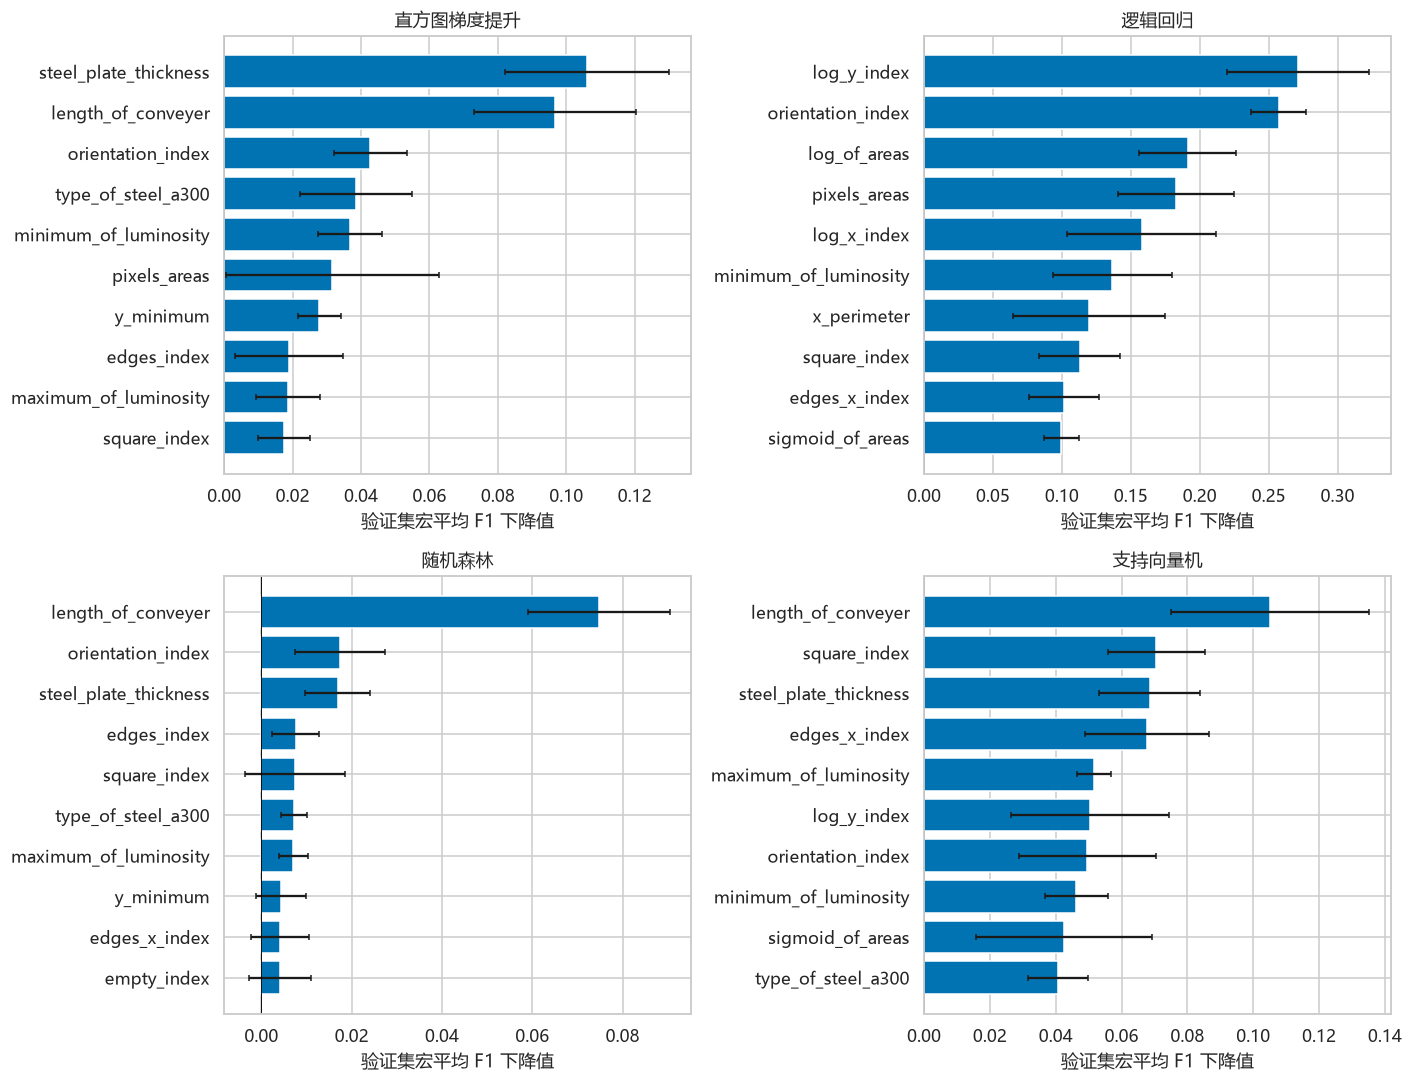

In [17]:
importance_rows=[]
fold_rechecks=[]
for _,row in comparison.iterrows():
    family=row.family
    for fold,(fit,val) in enumerate(folds,1):
        pipe=make_pipe(family,representative_params[family])
        with threadpool_limits(limits=1):
            pipe.fit(X.iloc[fit],y.iloc[fit]);check_preprocessing(pipe,X.iloc[fit])
            pred=pipe.predict(X.iloc[val])
            val_score=f1_score(y.iloc[val],pred,average='macro')
            imp=permutation_importance(pipe,X.iloc[val],y.iloc[val],scoring='f1_macro',
                n_repeats=PERMUTATION_REPEATS,random_state=SEED+fold,n_jobs=1)
        fold_rechecks.append({'family':family,'fold':fold,'validation_macro_f1':val_score})
        for feature,values in zip(X.columns,imp.importances):
            importance_rows.extend({'family':family,'fold':fold,'feature':feature,'repeat':i+1,
                'macro_f1_decrease':float(v)} for i,v in enumerate(values))
        table(pd.DataFrame(importance_rows),'permutation_importance_raw.csv')
        print('Permutation importance:',family,'fold',fold,'/5',flush=True)
importance_raw=pd.DataFrame(importance_rows)
importance_fold=importance_raw.groupby(['family','feature','fold']).macro_f1_decrease.mean().reset_index()
importance_summary=importance_fold.groupby(['family','feature']).macro_f1_decrease.agg(mean='mean',fold_sd='std').reset_index()
table(importance_summary,'permutation_importance_summary.csv')
table(pd.DataFrame(fold_rechecks),'representative_cv_recheck.csv')
for _,row in comparison.iterrows():
    actual=pd.DataFrame(fold_rechecks).query('family == @row.family').validation_macro_f1.mean()
    np.testing.assert_allclose(actual,row.validation_macro_f1,rtol=1e-9,atol=1e-9)
fig,axes=plt.subplots(2,2,figsize=(13,10))
for ax,(family,group) in zip(axes.flat,importance_summary.groupby('family')):
    top=group.nlargest(10,'mean').sort_values('mean')
    ax.barh(top.feature,top['mean'],xerr=top.fold_sd,capsize=2)
    ax.axvline(0,color='black',linewidth=.6)
    ax.set(title=family,xlabel='Validation macro F1 decrease')
fig.tight_layout();figure(fig,'05_permutation_importance.png')

## 7. 学习曲线与训练成本

SVM 使用 A 部分保存的嵌套子集；其余模型沿用 A 部分本次复现的曲线。内部验证数据参与过开发，因此曲线仅作诊断。完整拟合计时重复五次，内存沿用 A 部分的采样结果。

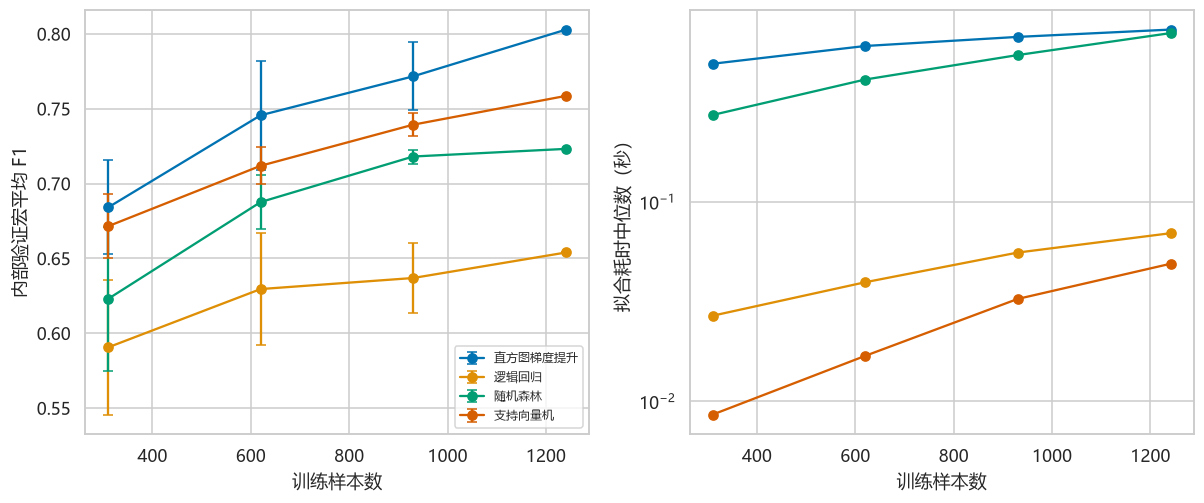

,模型,拟合中位数秒,拟合耗时下四分位数秒,拟合耗时上四分位数秒,模型体积KiB,最差轮P95毫秒
0,支持向量机,0.0710,0.0679,0.0730,272.4189,6.6865
1,逻辑回归,0.1179,0.1152,0.1181,4.8135,1.0841
2,随机森林,1.1516,1.1416,1.1545,8389.0254,12.4197
3,直方图梯度提升,1.1888,1.1887,1.1935,1316.4150,14.3249


In [18]:
subsets=pd.read_csv(ORIGINAL/'learning_subsets.csv')
learning_ids=pd.read_csv(ORIGINAL/'learning_validation_rows.csv').row_id.to_numpy()
assert set(learning_ids)<=training_ids
svm_learning=[]
for (repeat,fraction),group in subsets.groupby(['repeat','fraction']):
    ids=group.row_id.to_numpy()
    assert not set(ids)&set(learning_ids) and set(ids)<=training_ids
    pipe=make_pipe('SVM',svm_params)
    with threadpool_limits(limits=1):
        t=perf_counter();pipe.fit(X.loc[ids],y.loc[ids]);seconds=perf_counter()-t
        check_preprocessing(pipe,X.loc[ids])
        train_pred=pipe.predict(X.loc[ids]);val_pred=pipe.predict(X.loc[learning_ids])
    svm_learning.append({'family':'SVM','repeat':repeat,'fraction':fraction,'train_rows':len(ids),
        'train_macro_f1':f1_score(y.loc[ids],train_pred,average='macro'),
        'validation_macro_f1':f1_score(y.loc[learning_ids],val_pred,average='macro'),'fit_seconds':seconds,'source':'supplement'})
table(pd.DataFrame(svm_learning),'svm_learning_curve_raw.csv')
old_learning=pd.read_csv(ORIGINAL/'learning_curve_raw.csv')
old_learning=old_learning[old_learning.family!='RBF_SVC'].copy();old_learning['source']='original_CW2'
learning=pd.concat([old_learning,pd.DataFrame(svm_learning)],ignore_index=True)
table(learning,'combined_learning_curves.csv')
fig,axes=plt.subplots(1,2,figsize=(13,5))
for family,group in learning.groupby('family'):
    summary=group.groupby('train_rows').agg(train=('train_macro_f1','mean'),val=('validation_macro_f1','mean'),sd=('validation_macro_f1','std'),seconds=('fit_seconds','median'))
    axes[0].errorbar(summary.index,summary.val,yerr=summary.sd,marker='o',capsize=3,label=family)
    axes[1].plot(summary.index,summary.seconds,marker='o',label=family)
axes[0].set(xlabel='Training rows',ylabel='Internal validation macro F1')
axes[1].set(xlabel='Training rows',ylabel='Median fit seconds',yscale='log')
axes[0].legend(fontsize=8)
figure(fig,'06_updated_learning_curves.png')
cost_rows=[]
fit_times=[]
for _,row in comparison.iterrows():
    times=[]
    for repeat in range(1,6):
        pipe=make_pipe(row.family,representative_params[row.family])
        with threadpool_limits(limits=1):
            t=perf_counter();pipe.fit(X,y);elapsed=perf_counter()-t
        times.append(elapsed);fit_times.append({'family':row.family,'repeat':repeat,'fit_seconds':elapsed})
    model_path=RUN/f'{row.family}_representative.joblib'
    joblib.dump(timed_models[row.candidate_id],model_path)
    cost_rows.append({'family':row.family,'fit_median_seconds':float(np.median(times)),
        'fit_q25_seconds':float(np.quantile(times,.25)),'fit_q75_seconds':float(np.quantile(times,.75)),
        'serialized_kib':model_path.stat().st_size/1024,'worst_round_p95_ms':row.worst_round_p95_ms})
table(pd.DataFrame(fit_times),'fit_timing_raw.csv')
table(pd.DataFrame(cost_rows),'updated_resource_comparison.csv')
display(pd.DataFrame(cost_rows))

## B8 开发阶段检查

这些检查针对开发实验。冻结支持向量机的留出集结果见 D 部分。

In [19]:
checks={
    'development_rows_match_original':set(X.index)==training_ids,
    'no_holdout_rows_in_development':not bool(set(X.index)&excluded_ids),
    'both_kernels_compared':set(svm_results.kernel)=={'linear','rbf'},
    'every_candidate_accounted':len(rows)+len(failures)==len(params_by_id),
    'complete_candidates_have_five_folds':len(fold_rows)==5*len(rows),
    'every_oof_row_once':all(len(f)==1552 and f.row_id.is_unique for f in oof_frames),
    'all_four_families_compared':set(comparison.family)=={'SVM','LogisticRegression','RandomForest','HistGradientBoosting'},
    'each_timed_candidate_has_500_calls':all(len(g)==500 for _,g in pd.DataFrame(latency_rows).groupby('candidate_id')),
    'seven_class_curve_metrics':len(curve_metrics)==35,
    'importance_records_complete':len(importance_rows)==4*5*27*PERMUTATION_REPEATS,
    'svm_learning_fits_complete':len(svm_learning)==20,
    'test_predictions_not_written':not (RUN/'test_predictions.csv').exists(),
}
assert all(checks.values()),checks
save_json({'checks':checks,'passed':sum(checks.values()),'total':len(checks),'test_evaluations':0},'execution_verification.json')
original_hgb=old_comparison[old_comparison.family=='HistGradientBoosting'].iloc[0]
new_hgb=comparison[comparison.family=='HistGradientBoosting'].iloc[0]
summary=f"""# 支持向量机开发结果

- 搜索完成 {len(rows)} 个配置，另有 {len(failures)} 个未完成。
- 保留的 RBF 支持向量机：验证宏平均 F1 为 {svm_winner['validation_macro_f1']:.4f} ± {svm_winner['validation_macro_f1_std']:.4f}；最低折外召回率为 {svm_winner['oof_min_class_recall']:.4f}。
- 本次复现：支持向量机通过 {svm_winner['timing_rounds_passed']}/5 轮，最差 P95 为 {svm_winner['worst_round_p95_ms']:.3f} 毫秒；梯度提升通过 {new_hgb.timing_rounds_passed}/5 轮，最差 P95 为 {new_hgb.worst_round_p95_ms:.3f} 毫秒。
- 本次自动排序首位为 {translate_text(selected['family'])}。这只是复现描述，不是最终工程选型；开发阶段优选仍为冻结的 RBF 支持向量机。

历史计时见 C 部分，留出集结果见 D 部分。搜索预算不同，重复使用开发折调参可能造成乐观偏差。计时包含预处理，不含采集和特征提取；没有确定计时波动的原因。
"""
(RUN/'supplement_summary.md').write_text(summary,encoding='utf-8')
display(Markdown(summary))
save_json({'finished_at_utc':datetime.now(timezone.utc).isoformat(),'test_evaluations':0},'COMPLETED.json')
(ROOT/'results'/'latest_run.txt').write_text(RUN.name,encoding='utf-8')
print(f'Checks passed: {sum(checks.values())}/{len(checks)}. Results: {RUN}')

# 支持向量机开发结果

- 搜索完成 53 个配置，另有 6 个未完成。
- 保留的 RBF 支持向量机：验证宏平均 F1 为 0.7741 ± 0.0169；最低折外召回率为 0.6134。
- 本次复现：支持向量机通过 5/5 轮，最差 P95 为 6.686 毫秒；梯度提升通过 5/5 轮，最差 P95 为 14.325 毫秒。
- 本次自动排序首位为 直方图梯度提升。这只是复现描述，不是最终工程选型；开发阶段优选仍为冻结的 RBF 支持向量机。

历史计时见 C 部分，留出集结果见 D 部分。搜索预算不同，重复使用开发折调参可能造成乐观偏差。计时包含预处理，不含采集和特征提取；没有确定计时波动的原因。


检查通过： 12/12. 结果目录： .\supplement\results\20261115_170952_841582


## C 部分 选型与计时证据

两次历史实验中，支持向量机通过 10/10 轮计时，最差轮 P95 为 8.122 毫秒；梯度提升通过 8/10 轮，最差 P95 为 23.563 毫秒。梯度提升验证 F1 更高，为 0.8043，对比支持向量机的 0.7741；支持向量机的耗时余量更大。

修正后的历史实验自动排序以梯度提升为首位。后续选择支持向量机，是结合两次计时作出的工程判断，并非预先规定的十轮规则。新计时不改变冻结选择。实验没有记录能确定计时波动原因的证据。

复现差异见 reproduction_differences.csv 和 reproduction_diagnostics.json。输入哈希仍须严格一致，差异不改变冻结模型和阈值。

In [20]:
# 核对复现分数。
# 记录历史与本次结果的数值差异，不假设硬件完全相同。
ARCHIVE=INTEGRATED_ROOT/'archive/supplement_corrected'
historical=pd.read_csv(ARCHIVE/'updated_model_comparison.csv')
reproduction_rows=[]
for family in ['SVM','LogisticRegression','RandomForest','HistGradientBoosting']:
    old=historical.set_index('family').loc[family]
    now=comparison.set_index('family').loc[family]
    for metric in ['train_macro_f1','validation_macro_f1','oof_min_class_recall']:
        reproduction_rows.append({'family':family,'metric':metric,'historical':float(old[metric]),
            'reproduced':float(now[metric]),'difference':float(now[metric]-old[metric])})
reproduction_table=pd.DataFrame(reproduction_rows)
table(reproduction_table,'reproduction_differences.csv')
history=pd.read_csv(ARCHIVE/'cross_run_timing_audit.csv')
table(history,'historical_cross_run_timing.csv')
display(history[['run','family','rounds_passed','total_rounds','worst_round_p95_ms']])
print('Current reproduction timing (separate from historical selection):')
display(comparison[['family','validation_macro_f1','oof_min_class_recall','worst_round_p95_ms','timing_rounds_passed']])
# 核对冻结模型。
frozen=joblib.load(INTEGRATED_ROOT/'archive/frozen_RBF_SVM.joblib')
rep=timed_models[svm_winner['candidate_id']]
assert frozen[-1].get_params()==rep[-1].get_params()
np.testing.assert_array_equal(frozen.classes_,rep.classes_)
assert set(frozen.classes_)==set(classes)
def same_array(a,b):
    return bool(a.shape==b.shape and np.allclose(a,b,rtol=0,atol=1e-12))
diagnostics={'cv_scores_match_historical':bool((reproduction_table.difference.abs()<=1e-10).all()),
    'support_vectors_match':same_array(frozen[-1].support_vectors_,rep[-1].support_vectors_),
    'dual_coefficients_match':same_array(frozen[-1].dual_coef_,rep[-1].dual_coef_),
    'frozen_model_used_for_holdout_cache':True,'historical_decision_preserved':True}
save_json(diagnostics,'reproduction_diagnostics.json')
if not all(diagnostics.values()):
    print('Reproduction drift detected; review reproduction_differences.csv and diagnostics. Frozen results remain separate.')
assert not (BASE_RUN_DIR/'test_predictions.csv').exists()
SUPPLEMENT_RUN=RUN
save_json({'cv_reproduced':diagnostics['cv_scores_match_historical'],'original_candidates':48,
    'svm_complete':len(rows),'svm_failed':len(failures),
    'fixed_model_matches_reproduction':diagnostics['support_vectors_match'] and diagnostics['dual_coefficients_match'],
    'historical_decision_preserved':True,'holdout_predictions_so_far':0},'integration_checks_before_test.json')


,实验,模型,通过轮数,总轮数,最差轮P95毫秒
0,20261104_153815_292759,支持向量机,5,5,5.0546
1,20261104_153815_292759,逻辑回归,5,5,0.5823
2,20261104_153815_292759,随机森林,5,5,17.0487
3,20261104_153815_292759,直方图梯度提升,3,5,23.5632
4,20261104_154236_767611,支持向量机,5,5,8.1223
5,20261104_154236_767611,逻辑回归,5,5,1.3342
6,20261104_154236_767611,随机森林,5,5,15.8505
7,20261104_154236_767611,直方图梯度提升,5,5,18.5465


本次复现计时（与历史选型分开）：


,模型,验证集宏平均F1,最低类别折外召回率,最差轮P95毫秒,计时通过轮数
0,支持向量机,0.7741,0.6134,6.6865,5
1,逻辑回归,0.7144,0.5227,1.0841,5
2,随机森林,0.7722,0.6097,12.4197,5
3,直方图梯度提升,0.8043,0.6349,14.3249,5


## D 部分 冻结支持向量机的留出集评估

全部指标来自冻结模型的同一组已保存预测。重跑时先核对模型、数据集与样本编号的哈希，再读取已有记录。评估后不重新调参或更换模型。

这 389 条样本已用于 CW1 和原 CW2，不构成新的独立测试。Wilson 95% 区间描述召回率的不确定性，不能把未通过的点估计判定改为通过。

缺失或改动包内预测记录将停止运行。派生表格和图写入 reproduced_holdout/，保留原始 final_test/。

读取已有冻结留出集预测，不进行新的预测。


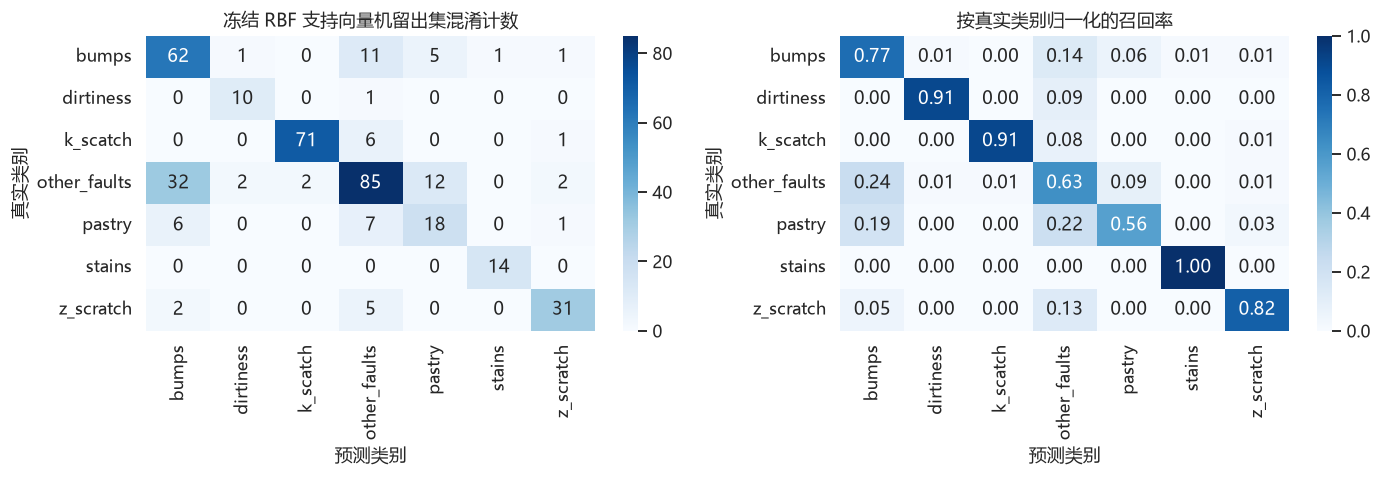

模型                                                                   SVM
参数                     {'kernel': 'rbf', 'C': 33.33333333333333, 'gam...
model_sha256           5673d3c6d259085c8546e5f0030ee69513ba5bc6d52e93...
dataset_sha256         9e9bfebd2ea8bf84f5264325fadace2194387991183cb2...
test_row_ids_sha256    610d3311372da8e34bea0663ad1b54c7092101c902af83...
predictions_sha256     b99a084a59cd1ef09783a34625ae5d2119a5c5cc354a73...
留出集预测次数                                                                1
评估UTC时间                                 2026-11-14T14:14:20.775991+00:00
留出集曾用于CW1                                                           True
留出集曾用于原CW2                                                          True
独立外部测试                                                             False
测试后调参                                                              False
样本数                                                                  389
留出集准确率                                             

,精确率,召回率,F1,样本数,召回率Wilson95%下限,召回率Wilson95%上限,召回率约束通过
bumps,0.6078,0.7654,0.6776,81.0,0.6625,0.8444,True
dirtiness,0.7692,0.9091,0.8333,11.0,0.6226,0.9838,True
k_scatch,0.9726,0.9103,0.9404,78.0,0.8262,0.9558,True
other_faults,0.7391,0.6296,0.6800,135.0,0.5456,0.7064,True
pastry,0.5143,0.5625,0.5373,32.0,0.3933,0.7183,False
stains,0.9333,1.0000,0.9655,14.0,0.7847,1.0000,True
z_scratch,0.8611,0.8158,0.8378,38.0,0.6658,0.9078,True


全部类别召回率达标： False
无论留出集结果如何，模型和参数均保持不变。


In [21]:
from sklearn.metrics import confusion_matrix
TEST_DIR=INTEGRATED_ROOT/'final_test'
TEST_REPLAY_DIR=INTEGRATED_ROOT/'reproduced_holdout'
TEST_REPLAY_DIR.mkdir(exist_ok=True)
model_path=INTEGRATED_ROOT/'archive/frozen_RBF_SVM.joblib'
model_hash=hashlib.sha256(model_path.read_bytes()).hexdigest()
assert model_hash==FROZEN_DECISION['model_sha256']
dataset_hash=hashlib.sha256(DATA.read_bytes()).hexdigest()
assert dataset_hash==EXPECTED
test_ids=pd.read_csv(BASE_RUN_DIR/'split_membership.csv')
test_ids=test_ids.loc[test_ids.split=='test','row_id'].to_numpy()
assert len(test_ids)==389 and len(set(test_ids))==389
assert not set(test_ids)&training_ids
test_rows=pd.read_csv(DATA).iloc[test_ids]
test_X=test_rows.drop(columns='fault_type')
test_y=test_rows.fault_type
row_hash=hashlib.sha256(test_ids.astype('<i8').tobytes()).hexdigest()
test_record=TEST_DIR/'test_metrics.json'
assert test_record.is_file(), 'Missing bundled frozen prediction record.'
test_metrics=json.loads(test_record.read_text())
assert test_metrics['model_sha256']==model_hash
assert test_metrics['dataset_sha256']==dataset_hash
assert test_metrics['test_row_ids_sha256']==row_hash
pred_frame=pd.read_csv(TEST_DIR/'test_predictions.csv')
assert hashlib.sha256((TEST_DIR/'test_predictions.csv').read_bytes()).hexdigest()==test_metrics['predictions_sha256']
np.testing.assert_array_equal(pred_frame.row_id,test_ids)
np.testing.assert_array_equal(pred_frame.truth,test_y.to_numpy())
test_pred=pred_frame.prediction.to_numpy()
print('Reusing the single frozen holdout prediction record; no new holdout prediction.')

test_classification=classification_report(test_y,test_pred,labels=classes,output_dict=True,zero_division=0)
test_detail=pd.DataFrame({c:test_classification[c] for c in classes}).T
test_cm=confusion_matrix(test_y,test_pred,labels=classes)
z=1.959963984540054
nn=test_detail.support.to_numpy();pp=test_detail.recall.to_numpy()
den=1+z*z/nn
center=(pp+z*z/(2*nn))/den
half=z*np.sqrt(pp*(1-pp)/nn+z*z/(4*nn*nn))/den
test_detail['recall_wilson95_low']=center-half
test_detail['recall_wilson95_high']=center+half
test_detail['recall_constraint_pass']=test_detail.recall>=MIN_RECALL
test_metrics.update({'test_accuracy':accuracy_score(test_y,test_pred),
 'test_macro_f1':f1_score(test_y,test_pred,average='macro'),
 'test_min_class_recall':float(test_detail.recall.min()),
 'test_recall_constraint_pass':bool(test_detail.recall.min()>=MIN_RECALL)})
(TEST_REPLAY_DIR/'test_metrics_recomputed.json').write_text(json.dumps(test_metrics,indent=2),encoding='utf8')
test_detail.rename_axis('class').reset_index().to_csv(TEST_REPLAY_DIR/'test_classification_report.csv',index=False,encoding='utf-8-sig')
pd.DataFrame(test_cm,index=classes,columns=classes).rename_axis('actual').reset_index().to_csv(TEST_REPLAY_DIR/'test_confusion_matrix.csv',index=False,encoding='utf-8-sig')
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
sns.heatmap(test_cm,annot=True,fmt='d',cmap='Blues',xticklabels=classes,yticklabels=classes,ax=axes[0])
sns.heatmap(test_cm/test_cm.sum(axis=1,keepdims=True),annot=True,fmt='.2f',vmin=0,vmax=1,cmap='Blues',xticklabels=classes,yticklabels=classes,ax=axes[1])
for ax,title in zip(axes,['Frozen RBF SVM holdout counts','Recall by actual class']):ax.set(xlabel='Predicted',ylabel='Actual',title=title)
localize_figure(fig)
fig.tight_layout();fig.savefig(TEST_REPLAY_DIR/'svm_test_confusion_matrix.png',dpi=180,bbox_inches='tight');plt.show();plt.close(fig)
display(pd.Series(test_metrics))
display(test_detail)
print('All-class recall threshold met:',test_metrics['test_recall_constraint_pass'])
print('Model and parameters remain unchanged regardless of the holdout result.')


## E 部分 结果与局限

折外召回率反映开发阶段表现；留出集召回率是另一项检查。pastry 未达到 0.60，因此不建议立即部署。本研究没有验证任何流水线满足全部约束。

In [22]:
metrics=json.loads((INTEGRATED_ROOT/'final_test/test_metrics.json').read_text())
final_summary=f"""# 最终结果

**RBF 支持向量机是开发阶段优选，尚不能直接部署。**

- 流水线：中位数填补、标准化和 RBF 支持向量机；参数为 {json.dumps(FROZEN_DECISION['params'])}。
- 验证宏平均 F1 为 {svm_winner['validation_macro_f1']:.4f} ± {svm_winner['validation_macro_f1_std']:.4f}；最低折外召回率为 {svm_winner['oof_min_class_recall']:.4f}。
- 留出集共 {metrics['rows']} 条，准确率为 {metrics['test_accuracy']:.4f}，宏平均 F1 为 {metrics['test_macro_f1']:.4f}。
- pastry 召回率为 18/32 = {metrics['test_min_class_recall']:.4f}，未通过每类至少 0.60 的要求；至少需要预测正确 20/32 条。

本研究没有验证任何流水线满足全部约束，不建议立即部署。测试后模型和阈值保持不变。留出集此前已被查看，不构成新的独立证据；重跑只读取经哈希核对的同一组预测。
"""
(INTEGRATED_ROOT/'results_summary.md').write_text(final_summary,encoding='utf8')
display(Markdown(final_summary))
verified_input_count=verify_inputs(INTEGRATED_ROOT)
checks={'package_inputs_unchanged':True,'one_test_prediction_record':metrics['test_evaluation_count']==1,
 'prediction_rows':len(pd.read_csv(INTEGRATED_ROOT/'final_test/test_predictions.csv'))==389,
 'base_test_not_executed':not (BASE_RUN_DIR/'test_predictions.csv').exists(),
 'final_params_unchanged':metrics['model_sha256']==FROZEN_DECISION['model_sha256']}
assert all(checks.values()),checks
(INTEGRATED_ROOT/'qa/integrated_checks.json').write_text(json.dumps({'checks':checks,
 'base_run':BASE_RUN_DIR.relative_to(INTEGRATED_ROOT).as_posix(),
 'supplement_run':SUPPLEMENT_RUN.relative_to(INTEGRATED_ROOT).as_posix(),
 'verified_input_count':verified_input_count,'complete':True},indent=2),encoding='utf8')
print('Integration checks:',checks)


# 最终结果

**RBF 支持向量机是开发阶段优选，尚不能直接部署。**

- 流水线：中位数填补、标准化和 RBF 支持向量机；参数为 {"kernel": "rbf", "C": 33.33333333333333, "gamma": 0.03, "class_weight": "balanced"}。
- 验证宏平均 F1 为 0.7741 ± 0.0169；最低折外召回率为 0.6134。
- 留出集共 389 条，准确率为 0.7481，宏平均 F1 为 0.7817。
- pastry 召回率为 18/32 = 0.5625，未通过每类至少 0.60 的要求；至少需要预测正确 20/32 条。

本研究没有验证任何流水线满足全部约束，不建议立即部署。测试后模型和阈值保持不变。留出集此前已被查看，不构成新的独立证据；重跑只读取经哈希核对的同一组预测。


整合检查： {'package_inputs_unchanged': True, 'one_test_prediction_record': True, 'prediction_rows': True, 'base_test_not_executed': True, 'final_params_unchanged': True}


## 后续改进

1. 使用开发集折外预测分析 pastry 错误，补充有代表性的样本并核查标签。
2. 在开发集交叉验证中比较针对性类别权重及邻近的 C、gamma，同时检查精确率、召回率、宏平均 F1 和耗时。
3. 冻结修改后的流水线，使用从未查看的新数据评估，优先采用不同生产批次，并在目标硬件上重新计时。


## 小组分工

| 成员 | 姓名 | 学号 | 职责 |
|---|---|---|---|
| A | Xianjie Zhang | 3271422Z | 基线与支持向量机复核、整合及推荐理由。 |
| B | Zhuo Liu | 3264500L | 随机森林复核、比较及展示整合。 |
| C | Yaotian Lei | 3191229L | 梯度提升、学习曲线、过拟合与参数取舍。 |
| D | Sun Peng | 3246696S | 数据、验证、实验设计与复现。 |
| E | Tao Jin | 3251660J | 计时、成本复核及最终冻结支持向量机评估。 |


**AI 工具及用途**

OpenAI Codex 辅助了代码生成与调试、notebook 整合、哈希与指标核对、冻结支持向量机评估。
